# Loan Default Prediction Using Machine Learning
## A Comparative Multi-Dataset Study Based on KDD Methodology
**Course:** Predictive Analytics — CA3 &nbsp;

---
### Abstract
This notebook studies loan-default prediction on **three independent datasets** — *Customer Behavior* (`Risk_Flag`), *Lending Club* (`Default`) and *Credit Risk* (`loan_status`). The datasets are **never merged**: each has its own target definition, population and leakage risks, so each is processed, modelled and evaluated separately and the results are compared only at the level of *methodology and metrics*. and from 0.  Environment setup and configuration rest same as file and output a=exact same
Three model families — **Logistic Regression, Random Forest and XGBoost** — are trained on every dataset (**3 × 3 = 9 models**), tuned with cross-validated randomized search, and evaluated on held-out data with Accuracy, Precision, Recall, F1, ROC-AUC, PR-AUC, confusion matrices and ROC / precision-recall curves.

### KDD process map
| KDD stage | Where in this notebook | Main activities |
|---|---|---|
| **1. Selection** | Section 1 | Locate/load files, validate targets, document which columns are kept or dropped and why |
| **2. Preprocessing** | Section 2 | Missing values, duplicates, implausible values, outliers, label-maturity check, class distribution, EDA |
| **3. Transformation** | Section 3 | Feature engineering, leakage-safe splitting, encoding, outlier clipping, imputation, scaling |
| **4. Data Mining** | Section 4 | Baseline models, hyper-parameter tuning, class-imbalance handling, final training of 9 models |
| **5. Evaluation / Interpretation** | Section 5 | Validation-based selection, held-out test results, curves, bootstrap CIs, importance, SHAP, leakage audits |
| *Knowledge use* | Sections 6–8 | Interactive widget interface, export, conclusions, limitations, future scope |


### How to run
1. Upload the three CSV files to Colab (`/content`) **or** set `MOUNT_DRIVE = True` in the first data cell and point `DATA_DIR` at the Drive folder that holds them (recommended: the Lending Club file is ~170 MB).
2. *Runtime → Run all.* A full run tunes nine models; expect roughly 20–45 minutes on a free CPU runtime. Set `QUICK_MODE = True` in the configuration cell for a fast smoke test (smaller samples, fewer search iterations — results will differ).
3. Nothing in this notebook is pre-computed: **every number, table and figure is produced when you run it on your files.**

> **Important:** the three targets measure different things on different populations, so scores must not be read as a like-for-like benchmark across datasets. This is an academic prototype, **not** a lending-decision system.

## 0. Environment setup and configuration

In [1]:
# Install only what is missing (Colab already ships with most packages)
import importlib, subprocess, sys
for pkg in ['xgboost', 'shap', 'ipywidgets']:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])
print('Dependencies ready.')

Dependencies ready.


In [2]:
import os, re, gc, time, json, zipfile, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import loguniform
from IPython.display import display, HTML, Markdown, clear_output

import sklearn
from sklearn.base import BaseEstimator, TransformerMixin, OneToOneFeatureMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import (train_test_split, StratifiedKFold, StratifiedGroupKFold,
                                     TimeSeriesSplit, RandomizedSearchCV)
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             average_precision_score, confusion_matrix, ConfusionMatrixDisplay,
                             roc_curve, precision_recall_curve)
from xgboost import XGBClassifier
import joblib

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=DeprecationWarning)

# ----------------------------- CONFIGURATION ---------------------------------
SEED = 42
QUICK_MODE = False          # True = fast smoke test with small samples (results will differ)
RUN_SHAP = True             # SHAP summary plots for the three XGBoost models

LC_TRAIN_CAP = 300_000      # max Lending Club TRAIN rows used for model fitting (val/test stay complete)
TUNE_CAP = 50_000           # rows used inside the hyper-parameter search
CV_FOLDS = 3
N_ITER = {'Logistic Regression': 8, 'Random Forest': 8, 'XGBoost': 10}
LC_CUTOFF = '2018-01-01'    # Lending Club loans issued on/after this date are excluded (label-maturity bias, see 2.4)
SHAP_SAMPLE = 1000
PERM_SAMPLE = 5000
BOOT_N, BOOT_CAP = 100, 50_000
RF_TREES = [100, 150, 200]

if QUICK_MODE:
    LC_TRAIN_CAP, TUNE_CAP = 60_000, 15_000
    N_ITER = {'Logistic Regression': 3, 'Random Forest': 2, 'XGBoost': 2}
    SHAP_SAMPLE, PERM_SAMPLE, BOOT_N, BOOT_CAP = 200, 1_000, 20, 10_000
    RF_TREES = [30, 50]

OUT_DIR = Path('/content/loan_default_outputs')
FIG_DIR = OUT_DIR / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)

DS = ['Customer Behavior', 'Lending Club', 'Credit Risk']
TARGET = {'Customer Behavior': 'Risk_Flag', 'Lending Club': 'Default', 'Credit Risk': 'loan_status'}
MODEL_KEYS = ['Logistic Regression', 'Random Forest', 'XGBoost']
MODEL_COLORS = {'Logistic Regression': '#4C72B0', 'Random Forest': '#55A868', 'XGBoost': '#C44E52'}

sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 100, 'axes.titlesize': 12, 'axes.titleweight': 'bold'})

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f'{name}.png', dpi=130, bbox_inches='tight')
    plt.show()

def mem_mb(df):
    return df.memory_usage(deep=True).sum() / 1024**2

print(f'scikit-learn {sklearn.__version__} | pandas {pd.__version__} | numpy {np.__version__}')
print('QUICK_MODE =', QUICK_MODE)

scikit-learn 1.6.1 | pandas 2.2.3 | numpy 2.1.3
QUICK_MODE = False


---
# STAGE 1 — SELECTION
**Goal:** decide which data and variables are relevant to the question "will this loan default?", load them memory-efficiently, and validate the target variables.

### 1.1 Locate and load the three datasets
File names are matched case-insensitively and tolerate spaces/underscores (`Training Data.csv` = `Training_Data.csv`). If a file is not found, an upload dialog opens. `Test_Data.csv` and `Sample_Prediction_Dataset.csv` (if you have them) contain **no labels** and are therefore not used for evaluation.

In [3]:
MOUNT_DRIVE = False                 # set True to read the CSVs from Google Drive
DATA_DIR = '/content'               # folder that contains the CSV files
if MOUNT_DRIVE:
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_DIR = '/content/drive/MyDrive'     # <-- change to the folder that holds your CSVs

FILES = {'Customer Behavior': 'training_data.csv',
         'Lending Club': 'lc_loans_granting_model_dataset.csv',
         'Credit Risk': 'credit_risk_dataset.csv'}

def _norm(name):
    return re.sub(r'[\s_]+', '_', name.lower())

def find_csvs():
    found = {}
    for d in [DATA_DIR, os.getcwd(), '/content']:
        if os.path.isdir(d):
            for f in os.listdir(d):
                for key, target in FILES.items():
                    if key not in found and _norm(f) == target:
                        found[key] = os.path.join(d, f)
    return found

paths = find_csvs()
missing = [k for k in FILES if k not in paths]
if missing:
    print('Not found:', missing, '-> opening upload dialog (large files upload faster via Google Drive).')
    from google.colab import files
    files.upload()
    paths = find_csvs()
missing = [k for k in FILES if k not in paths]
assert not missing, f'Still missing: {missing}. Upload the files or set DATA_DIR.'
for k, v in paths.items():
    print(f'{k:18s} -> {v}  ({os.path.getsize(v)/1024**2:,.1f} MB)')

Credit Risk        -> /content/credit_risk_dataset.csv  (1.7 MB)
Customer Behavior  -> /content/Training Data.csv  (19.2 MB)
Lending Club       -> /content/LC_loans_granting_model_dataset.csv  (159.7 MB)


In [4]:
# Memory-efficient loading: only the columns that can legitimately be used, compact dtypes for Lending Club.
LC_USECOLS = ['issue_d', 'revenue', 'dti_n', 'loan_amnt', 'fico_n', 'emp_length',
              'purpose', 'home_ownership_n', 'addr_state', 'Default']
LC_DTYPES = {'revenue': 'float32', 'dti_n': 'float32', 'loan_amnt': 'float32', 'fico_n': 'float32',
             'emp_length': 'category', 'purpose': 'category', 'home_ownership_n': 'category',
             'addr_state': 'category', 'Default': 'float32'}

raw = {}
raw['Customer Behavior'] = pd.read_csv(paths['Customer Behavior'])
raw['Lending Club'] = pd.read_csv(paths['Lending Club'], usecols=LC_USECOLS, dtype=LC_DTYPES)
raw['Credit Risk'] = pd.read_csv(paths['Credit Risk'])

# Header-only look at the Lending Club columns that are NOT loaded (kept out on purpose, see 1.3)
lc_all_cols = list(pd.read_csv(paths['Lending Club'], nrows=0).columns)
lc_not_loaded = [c for c in lc_all_cols if c not in LC_USECOLS]
lc_experience = pd.read_csv(paths['Lending Club'], usecols=['experience_c'])['experience_c']

overview = pd.DataFrame([{
    'Dataset': n, 'Rows': len(df), 'Columns loaded': df.shape[1], 'Target': TARGET[n],
    'Memory (MB)': round(mem_mb(df), 1)} for n, df in raw.items()])
display(overview)
for n, df in raw.items():
    print(f'\n=== {n} === first rows'); display(df.head(3))

,Dataset,Rows,Columns loaded,Target,Memory (MB)
0,Customer Behavior,252000,13,Risk_Flag,95.1
1,Lending Club,1347681,10,Default,104.1
2,Credit Risk,32581,12,loan_status,8.6



=== Customer Behavior === first rows


,Id,Income,Age,Experience,Married/Single,House_Ownership,Car_Ownership,Profession,CITY,STATE,CURRENT_JOB_YRS,CURRENT_HOUSE_YRS,Risk_Flag
0,1,1303834,23,3,single,rented,no,Mechanical_engineer,Rewa,Madhya_Pradesh,3,13,0
1,2,7574516,40,10,single,rented,no,Software_Developer,Parbhani,Maharashtra,9,13,0
2,3,3991815,66,4,married,rented,no,Technical_writer,Alappuzha,Kerala,4,10,0



=== Lending Club === first rows


,issue_d,revenue,dti_n,loan_amnt,fico_n,emp_length,purpose,home_ownership_n,addr_state,Default
0,Dec-2015,55000.0,5.910000,3600.0,677.0,10+ years,debt_consolidation,MORTGAGE,PA,0.0
1,Dec-2015,65000.0,16.059999,24700.0,717.0,10+ years,small_business,MORTGAGE,SD,0.0
2,Dec-2015,71000.0,13.850000,20000.0,697.0,10+ years,home_improvement,MORTGAGE,IL,0.0



=== Credit Risk === first rows


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3


### 1.2 Data inspection — structure, types, cardinality, target validation

In [5]:
def inspect(df, name):
    info = pd.DataFrame({'dtype': df.dtypes.astype(str), 'missing': df.isna().sum(),
                         'missing %': (df.isna().mean() * 100).round(2), 'unique': df.nunique()})
    print(f'\n{"="*70}\n{name}: {df.shape[0]:,} rows x {df.shape[1]} columns\n{"="*70}')
    display(info)
    num = df.select_dtypes(include='number')
    display(num.describe(percentiles=[.01, .5, .99]).T.round(3))

for n, df in raw.items():
    inspect(df, n)

# Target validation
print('\nTarget validation')
for n, df in raw.items():
    t = TARGET[n]
    vc = df[t].value_counts(dropna=False)
    print(f'  {n:18s} {t:12s} values={dict(vc)}')
    assert set(df[t].dropna().unique()) <= {0, 1, 0.0, 1.0}, f'{t} is not binary 0/1'


Customer Behavior: 252,000 rows x 13 columns


,dtype,missing,missing %,unique
Id,int64,0,0.0,252000
Income,int64,0,0.0,41920
Age,int64,0,0.0,59
Experience,int64,0,0.0,21
Married/Single,object,0,0.0,2
House_Ownership,object,0,0.0,3
Car_Ownership,object,0,0.0,2
Profession,object,0,0.0,51
CITY,object,0,0.0,317
STATE,object,0,0.0,29


,count,mean,std,min,1%,50%,99%,max
Id,252000.0,126000.500,72746.278,1.0,2520.99,126000.5,249480.01,252000.0
Income,252000.0,4997116.665,2878311.014,10310.0,112513.00,5000694.5,9884599.00,9999938.0
Age,252000.0,49.954,17.064,21.0,21.00,50.0,79.00,79.0
Experience,252000.0,10.084,6.003,0.0,0.00,10.0,20.00,20.0
CURRENT_JOB_YRS,252000.0,6.334,3.647,0.0,0.00,6.0,14.00,14.0
CURRENT_HOUSE_YRS,252000.0,11.998,1.399,10.0,10.00,12.0,14.00,14.0
Risk_Flag,252000.0,0.123,0.328,0.0,0.00,0.0,1.00,1.0



Lending Club: 1,347,681 rows x 10 columns


,dtype,missing,missing %,unique
issue_d,object,0,0.0,139
revenue,float32,0,0.0,65608
dti_n,float32,0,0.0,7068
loan_amnt,float32,0,0.0,1560
fico_n,float32,0,0.0,48
emp_length,category,0,0.0,12
purpose,category,0,0.0,14
home_ownership_n,category,0,0.0,4
addr_state,category,0,0.0,51
Default,float32,0,0.0,2


,count,mean,std,min,1%,50%,99%,max
revenue,1347681.0,77369.688,70320.984,1896.0,19000.0,65000.00,260000.00,10999200.0
dti_n,1347681.0,18.299,11.147,0.0,1.8,17.63,38.48,999.0
loan_amnt,1347681.0,14408.230,8721.926,500.0,1500.0,12000.00,35000.00,40000.0
fico_n,1347681.0,698.159,31.803,612.0,662.0,692.00,802.00,847.5
Default,1347681.0,0.200,0.402,0.0,0.0,0.00,1.00,1.0



Credit Risk: 32,581 rows x 12 columns


,dtype,missing,missing %,unique
person_age,int64,0,0.00,58
person_income,int64,0,0.00,4295
person_home_ownership,object,0,0.00,4
person_emp_length,float64,895,2.75,36
loan_intent,object,0,0.00,6
loan_grade,object,0,0.00,7
loan_amnt,int64,0,0.00,753
loan_int_rate,float64,3116,9.56,348
loan_status,int64,0,0.00,2
loan_percent_income,float64,0,0.00,77


,count,mean,std,min,1%,50%,99%,max
person_age,32581.0,27.735,6.348,20.00,21.00,26.00,50.00,144.00
person_income,32581.0,66074.848,61983.119,4000.00,14400.00,55000.00,225200.00,6000000.00
person_emp_length,31686.0,4.790,4.143,0.00,0.00,4.00,18.00,123.00
loan_amnt,32581.0,9589.371,6322.087,500.00,1000.00,8000.00,29800.00,35000.00
loan_int_rate,29465.0,11.012,3.240,5.42,5.42,10.99,18.62,23.22
loan_status,32581.0,0.218,0.413,0.00,0.00,0.00,1.00,1.00
loan_percent_income,32581.0,0.170,0.107,0.00,0.02,0.15,0.50,0.83
cb_person_cred_hist_length,32581.0,5.804,4.055,2.00,2.00,4.00,17.00,30.00



Target validation
  Customer Behavior  Risk_Flag    values={0: np.int64(221004), 1: np.int64(30996)}
  Lending Club       Default      values={0.0: np.int64(1078432), 1.0: np.int64(269249)}
  Credit Risk        loan_status  values={0: np.int64(25473), 1: np.int64(7108)}


### 1.3 Selection decisions — which variables are used and why
The table is generated from the loaded data so that the reasoning is traceable.

In [6]:
lc_exp_vc = lc_experience.value_counts().to_dict()
sel_rows = [
 ('Customer Behavior', 'Id', 'Dropped', 'Row identifier — no predictive meaning'),
 ('Customer Behavior', 'Income, Age, Experience, CURRENT_JOB_YRS, CURRENT_HOUSE_YRS', 'Selected', 'Applicant-level numeric attributes'),
 ('Customer Behavior', 'Married/Single, House_Ownership, Car_Ownership', 'Selected', 'Low-cardinality categorical attributes'),
 ('Customer Behavior', 'Profession, CITY, STATE', 'Selected', 'High-cardinality categoricals (encoded with leakage-safe target encoding)'),
 ('Lending Club', 'id', 'Dropped', 'Row identifier'),
 ('Lending Club', 'title, desc', 'Dropped', 'Free text; `desc` is almost entirely empty in the provided file'),
 ('Lending Club', 'zip_code', 'Dropped', 'Very high-cardinality, redundant with addr_state'),
 ('Lending Club', 'experience_c', 'Dropped', f'Near-constant (value counts: {lc_exp_vc}) — carries no usable signal'),
 ('Lending Club', 'issue_d', 'Used for splitting only', 'Origination month drives the chronological split; NOT a model feature (would not extrapolate)'),
 ('Lending Club', 'revenue, dti_n, loan_amnt, fico_n, emp_length, purpose, home_ownership_n, addr_state', 'Selected', 'Application-time borrower/loan attributes'),
 ('Credit Risk', 'person_*, loan_*, cb_person_*', 'Selected', 'All 11 predictors are kept; `loan_grade` / `loan_int_rate` are underwriting outputs (leakage-sensitivity tested in Section 5.9)'),
]
selection_table = pd.DataFrame(sel_rows, columns=['Dataset', 'Column(s)', 'Decision', 'Reason'])
pd.set_option('display.max_colwidth', 120)
display(selection_table)
print('Lending Club columns present in the CSV but not loaded:', lc_not_loaded)
del lc_experience; gc.collect()

,Dataset,Column(s),Decision,Reason
0,Customer Behavior,Id,Dropped,Row identifier — no predictive meaning
1,Customer Behavior,"Income, Age, Experience, CURRENT_JOB_YRS, CURRENT_HOUSE_YRS",Selected,Applicant-level numeric attributes
2,Customer Behavior,"Married/Single, House_Ownership, Car_Ownership",Selected,Low-cardinality categorical attributes
3,Customer Behavior,"Profession, CITY, STATE",Selected,High-cardinality categoricals (encoded with leakage-safe target encoding)
4,Lending Club,id,Dropped,Row identifier
5,Lending Club,"title, desc",Dropped,Free text; `desc` is almost entirely empty in the provided file
6,Lending Club,zip_code,Dropped,"Very high-cardinality, redundant with addr_state"
7,Lending Club,experience_c,Dropped,"Near-constant (value counts: {1: 1347656, 0: 25}) — carries no usable signal"
8,Lending Club,issue_d,Used for splitting only,Origination month drives the chronological split; NOT a model feature (would not extrapolate)
9,Lending Club,"revenue, dti_n, loan_amnt, fico_n, emp_length, purpose, home_ownership_n, addr_state",Selected,Application-time borrower/loan attributes


Lending Club columns present in the CSV but not loaded: ['id', 'experience_c', 'zip_code', 'title', 'desc']


30

---
# STAGE 2 — PREPROCESSING
**Goal:** find and treat data-quality problems using **deterministic, row-wise rules only**. Anything that must be *learned* from data (medians, clip bounds, encoders, scalers) is deferred to Stage 3 and fitted on the training split only — this keeps the preprocessing leakage-safe.

### 2.1 Missing values

In [7]:
rows = []
for n, df in raw.items():
    miss = df.isna().sum()
    for c, k in miss[miss > 0].items():
        rows.append({'Dataset': n, 'Column': c, 'Missing': int(k), 'Missing %': round(100 * k / len(df), 2)})
# Lending Club: 'NI' in emp_length is a coded "not indicated" value, i.e. a hidden missing value
ni = int((raw['Lending Club']['emp_length'].astype(object) == 'NI').sum())
rows.append({'Dataset': 'Lending Club', 'Column': "emp_length == 'NI' (coded missing)", 'Missing': ni,
             'Missing %': round(100 * ni / len(raw['Lending Club']), 2)})
miss_table = pd.DataFrame(rows)
display(miss_table if len(miss_table) else 'No missing values found.')
print('Treatment: handled inside the pipelines (median imputation + missing-indicator columns for numerics,'
      ' most-frequent for categoricals), fitted on training data only.')

,Dataset,Column,Missing,Missing %
0,Credit Risk,person_emp_length,895,2.75
1,Credit Risk,loan_int_rate,3116,9.56
2,Lending Club,emp_length == 'NI' (coded missing),78188,5.80


Treatment: handled inside the pipelines (median imputation + missing-indicator columns for numerics, most-frequent for categoricals), fitted on training data only.


### 2.2 Duplicates and implausible values
* **Customer Behavior:** the `Id` column makes every row unique, so we check duplicates *over the real features*. If many rows share an identical feature vector, a random train/test split would put the *same* profile on both sides — a hidden form of leakage.
* **Credit Risk:** known data-entry errors (ages > 100, employment length far beyond working life).

In [8]:
# ---- Customer Behavior: duplicate feature profiles --------------------------------
CUST_FEATS = [c for c in raw['Customer Behavior'].columns if c not in ('Id', 'Risk_Flag')]
cdf = raw['Customer Behavior']
profile_id = cdf.groupby(CUST_FEATS, sort=False).ngroup()
prof = pd.DataFrame({'pid': profile_id, 'y': cdf['Risk_Flag']}).groupby('pid')['y'].agg(['size', 'nunique'])
cust_audit = pd.DataFrame([{
    'Rows': len(cdf), 'Unique feature profiles': len(prof),
    'Rows sharing a profile with >=1 other row': int(prof.loc[prof['size'] > 1, 'size'].sum()),
    'Profiles with conflicting labels': int((prof['nunique'] > 1).sum()),
    'Max rows in one profile': int(prof['size'].max())}])
print('Customer Behavior — duplicate-profile audit (features only, Id and target excluded)')
display(cust_audit)

# ---- Other datasets: exact duplicate rows ----------------------------------------
lc_dups = int(raw['Lending Club'].duplicated().sum())
cr_dups = int(raw['Credit Risk'].duplicated().sum())
print(f'Lending Club exact duplicate rows: {lc_dups:,} | Credit Risk exact duplicate rows: {cr_dups:,}')

# ---- Credit Risk: implausible values ------------------------------------------------
cr = raw['Credit Risk']
bad_age = (cr['person_age'] < 18) | (cr['person_age'] > 100)
bad_emp = (cr['person_emp_length'] < 0) | (cr['person_emp_length'] > 60) | (cr['person_emp_length'] > cr['person_age'] - 14)
print(f'Credit Risk implausible age (<18 or >100): {int(bad_age.sum())} | implausible employment length '
      f'(<0, >60, or starting before age 14): {int(bad_emp.sum())}')
display(cr.loc[bad_age | bad_emp, ['person_age', 'person_emp_length', 'person_income']].head(8))

Customer Behavior — duplicate-profile audit (features only, Id and target excluded)


,Rows,Unique feature profiles,Rows sharing a profile with >=1 other row,Profiles with conflicting labels,Max rows in one profile
0,252000,42007,215993,1183,40


Lending Club exact duplicate rows: 0 | Credit Risk exact duplicate rows: 165
Credit Risk implausible age (<18 or >100): 5 | implausible employment length (<0, >60, or starting before age 14): 2


,person_age,person_emp_length,person_income
0,22,123.0,59000
81,144,4.0,250000
183,144,4.0,200000
210,21,123.0,192000
575,123,2.0,80004
747,123,7.0,78000
32297,144,12.0,6000000


**Observation → decision.** The audit above shows the feature space of Customer Behavior is heavily duplicated. We therefore keep all rows (they are not necessarily errors) but **split by profile** in Stage 3 (all rows with the same feature vector go to the same partition) and later quantify, in Section 5.9, how much a naive random split would have inflated the scores.

### 2.3 Outlier analysis
IQR-fence counts and quantiles are reported for the main numeric variables; box-plots use a log scale where the distribution is heavy-tailed. Outliers are **not deleted** (they can be genuine high-risk applicants). Instead the pipeline winsorises numeric inputs at the 0.1 % / 99.9 % quantiles **learned on the training split** (Stage 3), which protects Logistic Regression without touching the tree models' behaviour.

,Dataset,Feature,Min,P1,Median,P99,P99.9,Max,IQR outliers,IQR outliers %
0,Customer Behavior,Income,10310.00,112513.00,5000694.50,9884599.00,9985581.00,9999938.00,0,0.00
1,Customer Behavior,Age,21.00,21.00,50.00,79.00,79.00,79.00,0,0.00
2,Customer Behavior,Experience,0.00,0.00,10.00,20.00,20.00,20.00,0,0.00
3,Customer Behavior,CURRENT_JOB_YRS,0.00,0.00,6.00,14.00,14.00,14.00,0,0.00
4,Customer Behavior,CURRENT_HOUSE_YRS,10.00,10.00,12.00,14.00,14.00,14.00,0,0.00
5,Lending Club,revenue,1896.00,19000.00,65000.00,260000.00,585000.00,10999200.00,62998,4.67
6,Lending Club,dti_n,0.00,1.80,17.63,38.48,66.00,999.00,5506,0.41
7,Lending Club,loan_amnt,500.00,1500.00,12000.00,35000.00,40000.00,40000.00,7131,0.53
8,Lending Club,fico_n,612.00,662.00,692.00,802.00,832.00,847.50,46490,3.45
9,Credit Risk,person_age,20.00,21.00,26.00,50.00,66.00,144.00,1494,4.59


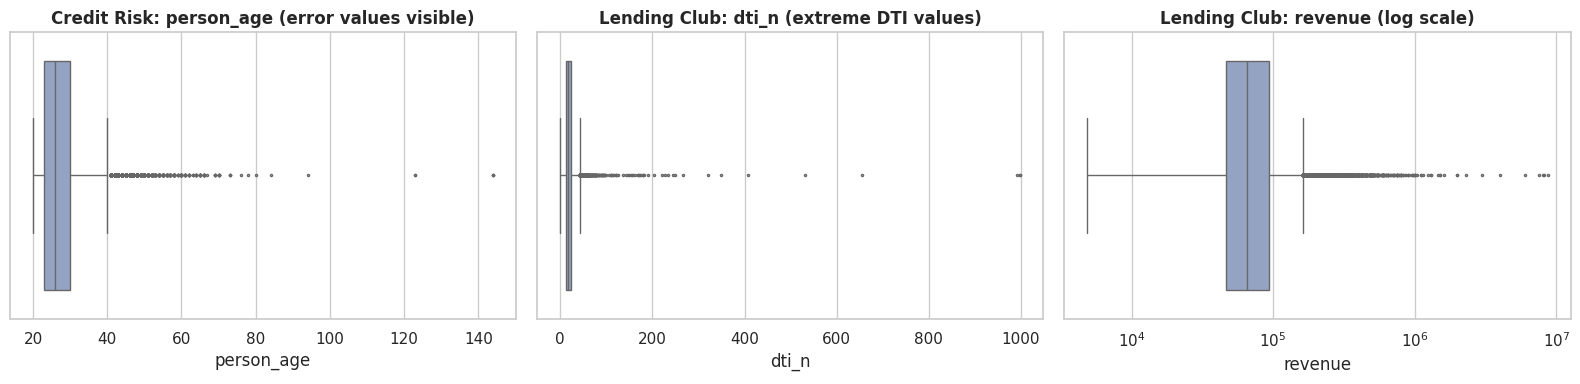

In [9]:
OUTLIER_COLS = {
    'Customer Behavior': ['Income', 'Age', 'Experience', 'CURRENT_JOB_YRS', 'CURRENT_HOUSE_YRS'],
    'Lending Club': ['revenue', 'dti_n', 'loan_amnt', 'fico_n'],
    'Credit Risk': ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate'],
}
orows = []
for n, cols in OUTLIER_COLS.items():
    df = raw[n]
    for c in cols:
        s = df[c].astype('float64').dropna()
        q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
        lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        orows.append({'Dataset': n, 'Feature': c, 'Min': s.min(), 'P1': s.quantile(.01), 'Median': s.median(),
                      'P99': s.quantile(.99), 'P99.9': s.quantile(.999), 'Max': s.max(),
                      'IQR outliers': int(((s < lo) | (s > hi)).sum()),
                      'IQR outliers %': round(100 * ((s < lo) | (s > hi)).mean(), 2)})
outlier_table = pd.DataFrame(orows)
display(outlier_table.round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
def _box(ax, df, col, title, logx=False):
    s = df[col].astype('float64').dropna()
    s = s.sample(min(len(s), 100_000), random_state=SEED)
    sns.boxplot(x=s, ax=ax, color='#8DA0CB', fliersize=1.5)
    if logx: ax.set_xscale('log')
    ax.set_title(title)
_box(axes[0], raw['Credit Risk'], 'person_age', 'Credit Risk: person_age (error values visible)')
_box(axes[1], raw['Lending Club'], 'dti_n', 'Lending Club: dti_n (extreme DTI values)', logx=False)
_box(axes[2], raw['Lending Club'], 'revenue', 'Lending Club: revenue (log scale)', logx=True)
save_fig('02_outlier_boxplots')

### 2.4 Label-maturity check for Lending Club (why 2018 is excluded)
A loan issued recently has had little time to default. If the file only contains loans whose outcome is already known, recent vintages are biased towards early repayment and the default rate artificially collapses. Plotting the default rate by issue quarter makes this visible and justifies the cut-off `LC_CUTOFF` set in the configuration cell.

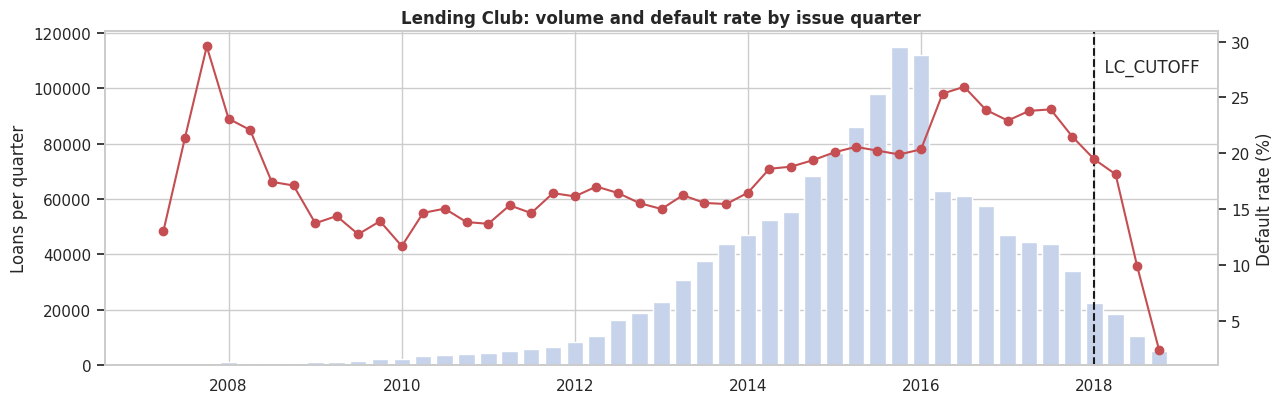

            loans  default_rate
issue_d                        
2017-01-01  46858         0.229
2017-04-01  44456         0.238
2017-07-01  43777         0.239
2017-10-01  34026         0.215
2018-01-01  22457         0.195
2018-04-01  18404         0.181
2018-07-01  10281         0.099
2018-10-01   5018         0.024


1597

In [10]:
_lc = raw['Lending Club'][['issue_d', 'Default']].copy()
_lc['issue_d'] = pd.to_datetime(_lc['issue_d'].astype(str), format='%b-%Y', errors='coerce')
_lc = _lc.dropna()
q = _lc.groupby(_lc['issue_d'].dt.to_period('Q')).agg(loans=('Default', 'size'), default_rate=('Default', 'mean'))
q.index = q.index.to_timestamp()

fig, ax1 = plt.subplots(figsize=(13, 4.2))
ax1.bar(q.index, q['loans'], width=70, color='#C7D3EA', label='Loans issued')
ax1.set_ylabel('Loans per quarter')
ax2 = ax1.twinx(); ax2.grid(False)
ax2.plot(q.index, q['default_rate'] * 100, color='#C44E52', marker='o', label='Default rate (%)')
ax2.set_ylabel('Default rate (%)')
ax1.axvline(pd.Timestamp(LC_CUTOFF), color='k', ls='--')
ax1.text(pd.Timestamp(LC_CUTOFF), ax1.get_ylim()[1] * .92, '  LC_CUTOFF', va='top')
ax1.set_title('Lending Club: volume and default rate by issue quarter')
save_fig('02_lc_default_by_quarter')
print(q.tail(8).round(3))
del _lc, q; gc.collect()

### 2.5 Apply the deterministic cleaning rules
| Dataset | Rules applied |
|---|---|
| Customer Behavior | Drop `Id`; attach `profile_id` (used **only** for group-aware splitting, never as a feature) |
| Lending Club | Drop rows with missing target/date; parse `issue_d`; exclude loans issued on/after `LC_CUTOFF` |
| Credit Risk | Drop exact duplicate rows; set implausible `person_age` and `person_emp_length` values to missing (imputed later inside the pipeline) |

In [11]:
clean = {}

# --- Customer Behavior
c = raw['Customer Behavior'].drop(columns=['Id']).dropna(subset=['Risk_Flag']).copy()
c['Risk_Flag'] = c['Risk_Flag'].astype('int8')
c['profile_id'] = profile_id.values          # group key for leakage-safe splitting only
clean['Customer Behavior'] = c

# --- Lending Club
lc = raw['Lending Club'].dropna(subset=['Default']).copy()
lc['Default'] = lc['Default'].astype('int8')
lc['issue_d'] = pd.to_datetime(lc['issue_d'].astype(str), format='%b-%Y', errors='coerce')
lc = lc.dropna(subset=['issue_d'])
n0 = len(lc)
lc = lc[lc['issue_d'] < pd.Timestamp(LC_CUTOFF)].reset_index(drop=True)
print(f'Lending Club: removed {n0 - len(lc):,} loans issued on/after {LC_CUTOFF}; {len(lc):,} remain')
clean['Lending Club'] = lc

# --- Credit Risk
cr = raw['Credit Risk'].drop_duplicates().copy()
bad_emp = (cr['person_emp_length'] < 0) | (cr['person_emp_length'] > 60) | (cr['person_emp_length'] > cr['person_age'] - 14)
bad_age = (cr['person_age'] < 18) | (cr['person_age'] > 100)
cr.loc[bad_emp, 'person_emp_length'] = np.nan
cr.loc[bad_age, 'person_age'] = np.nan
cr = cr.reset_index(drop=True)
print(f'Credit Risk: dropped {len(raw["Credit Risk"]) - len(cr)} duplicates; masked {int(bad_age.sum())} ages and {int(bad_emp.sum())} employment lengths')
clean['Credit Risk'] = cr

del raw, cdf, cr, lc, c, profile_id; gc.collect()
print()
for n, df in clean.items():
    print(f'{n:18s} rows={len(df):>9,}  default rate={df[TARGET[n]].mean():.2%}  memory={mem_mb(df):,.0f} MB')

Lending Club: removed 56,160 loans issued on/after 2018-01-01; 1,291,521 remain
Credit Risk: dropped 165 duplicates; masked 5 ages and 2 employment lengths

Customer Behavior  rows=  252,000  default rate=12.30%  memory=93 MB
Lending Club       rows=1,291,521  default rate=20.16%  memory=36 MB
Credit Risk        rows=   32,416  default rate=21.87%  memory=9 MB


### 2.6 Class distribution (imbalance)

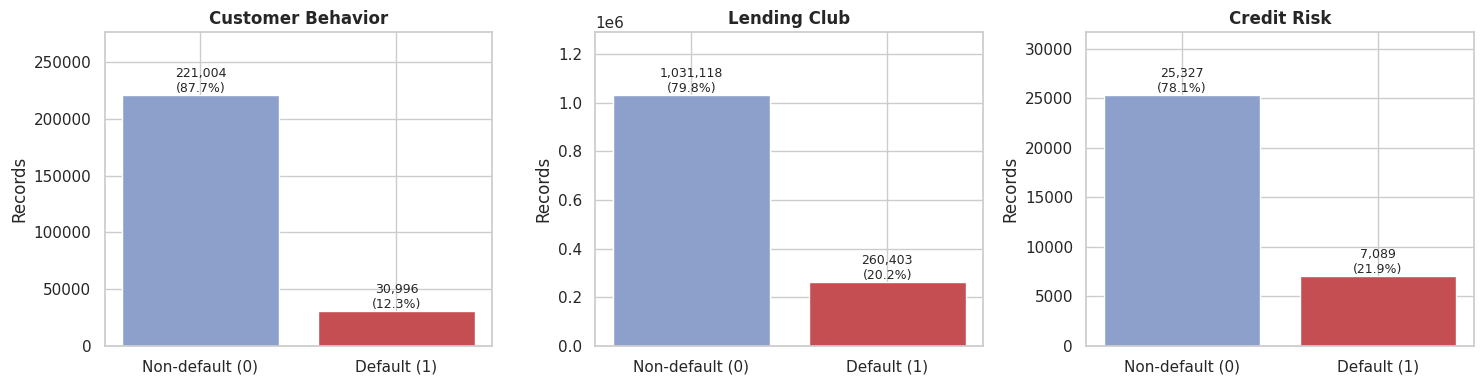

,Dataset,Non-default,Default,Default rate %,Imbalance ratio (neg:pos)
0,Customer Behavior,221004,30996,12.30,7.13
1,Lending Club,1031118,260403,20.16,3.96
2,Credit Risk,25327,7089,21.87,3.57


Handling: class weights (Logistic Regression / Random Forest) and scale_pos_weight (XGBoost); PR-AUC is the primary selection metric; thresholds are tuned on the validation set (Section 4.5 compares with no weighting).


In [12]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
imb_rows = []
for ax, n in zip(axes, DS):
    y = clean[n][TARGET[n]]
    vc = y.value_counts().sort_index()
    ax.bar(['Non-default (0)', 'Default (1)'], vc.values, color=['#8DA0CB', '#C44E52'])
    for i, v in enumerate(vc.values):
        ax.text(i, v, f'{v:,}\n({v/len(y):.1%})', ha='center', va='bottom', fontsize=9)
    ax.set_ylim(0, vc.max() * 1.25); ax.set_title(n); ax.set_ylabel('Records')
    imb_rows.append({'Dataset': n, 'Non-default': int(vc[0]), 'Default': int(vc[1]),
                     'Default rate %': round(100 * y.mean(), 2), 'Imbalance ratio (neg:pos)': round(vc[0] / vc[1], 2)})
save_fig('02_class_distribution')
imbalance_table = pd.DataFrame(imb_rows); display(imbalance_table)
print('Handling: class weights (Logistic Regression / Random Forest) and scale_pos_weight (XGBoost); '
      'PR-AUC is the primary selection metric; thresholds are tuned on the validation set (Section 4.5 compares with no weighting).')

### 2.7 Exploratory data analysis (EDA)
EDA is descriptive and uses at most 100 000 randomly sampled rows per dataset; no statistics from it feed the models.

**Numeric variables by class** (density-normalised so the minority class is visible; display clipped at the 99th percentile):

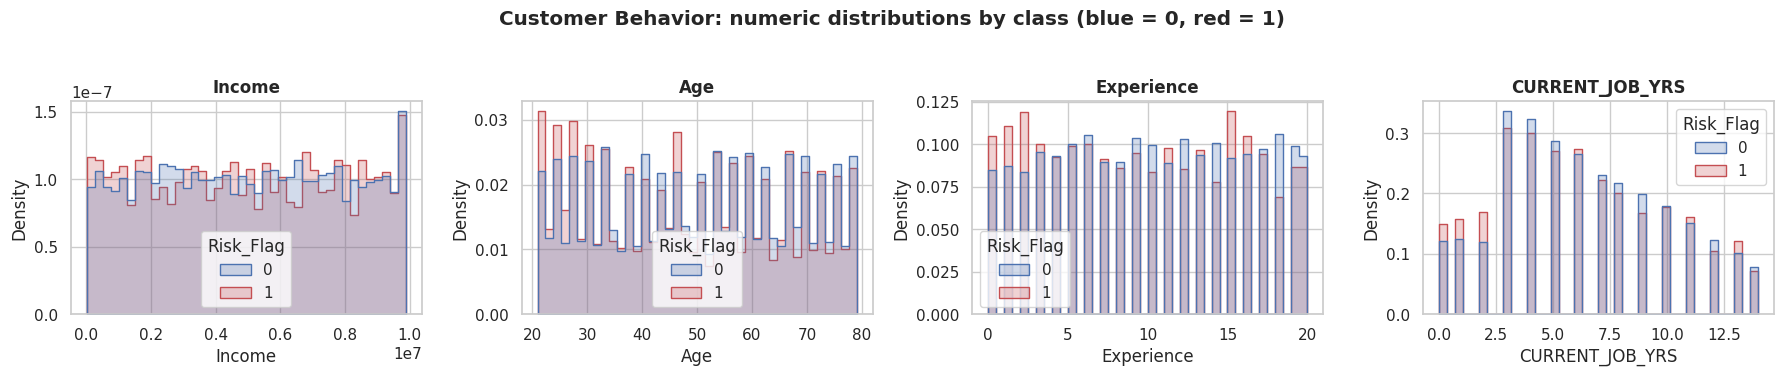

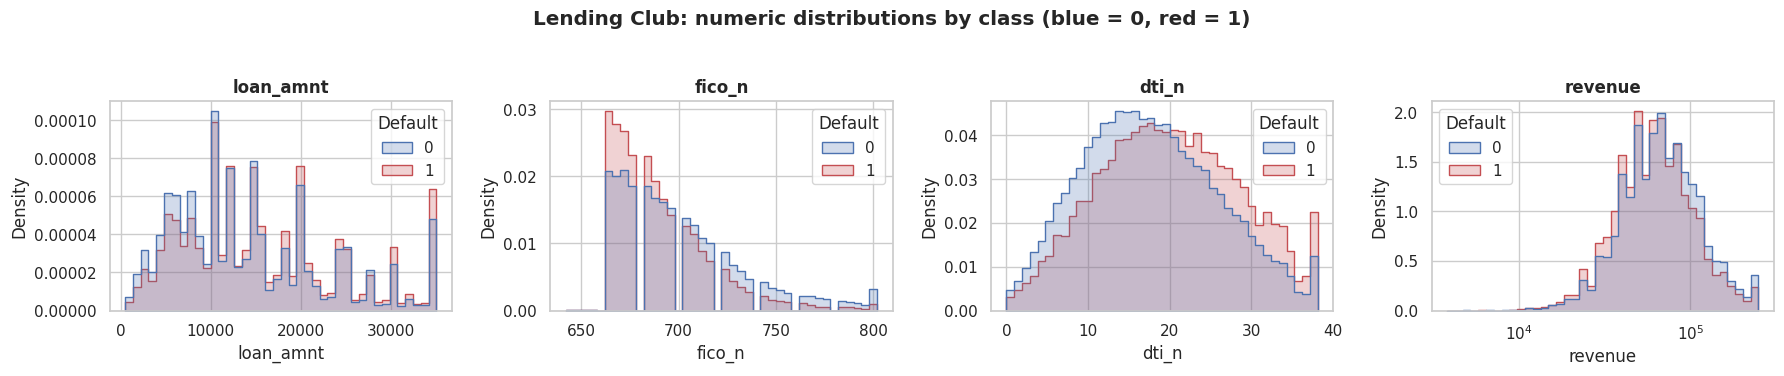

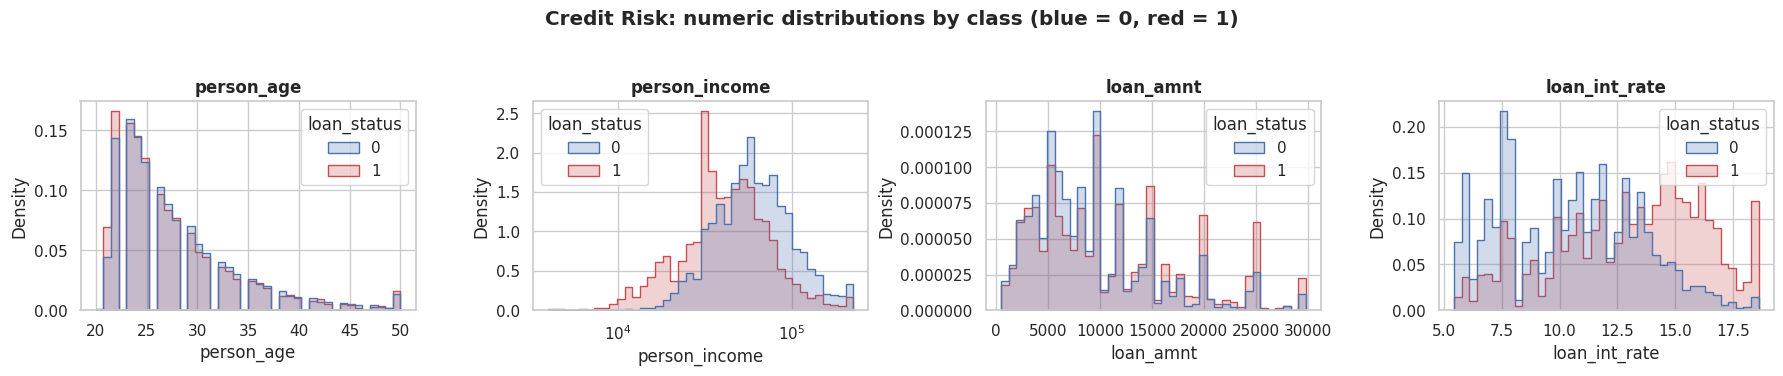

In [13]:
def sample_df(df, n=100_000):
    return df.sample(n=min(n, len(df)), random_state=SEED)

NUM_EDA = {
    'Customer Behavior': [('Income', False), ('Age', False), ('Experience', False), ('CURRENT_JOB_YRS', False)],
    'Lending Club': [('loan_amnt', False), ('fico_n', False), ('dti_n', False), ('revenue', True)],
    'Credit Risk': [('person_age', False), ('person_income', True), ('loan_amnt', False), ('loan_int_rate', False)],
}
for n in DS:
    t = TARGET[n]; s = sample_df(clean[n])
    fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))
    for ax, (col, logx) in zip(axes, NUM_EDA[n]):
        d = s[[col, t]].dropna().copy()
        d[col] = d[col].astype('float64').clip(upper=d[col].astype('float64').quantile(.99))
        if logx: d = d[d[col] > 0]
        sns.histplot(data=d, x=col, hue=t, bins=40, stat='density', common_norm=False, element='step',
                     log_scale=logx, ax=ax, palette={0: '#4C72B0', 1: '#C44E52'})
        ax.set_title(col)
    fig.suptitle(f'{n}: numeric distributions by class (blue = 0, red = 1)', y=1.04, fontweight='bold')
    save_fig(f'02_eda_numeric_{n.lower().replace(" ", "_")}')

**Categorical variables — default rate by category** (categories with at least 1 % support; dashed line = overall default rate):

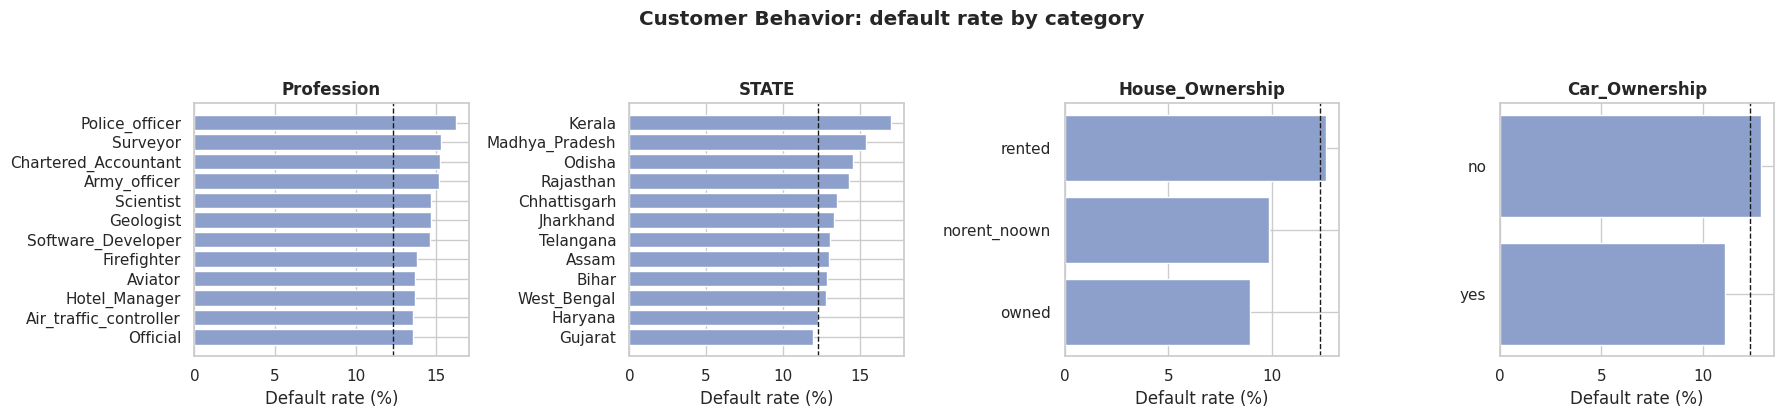

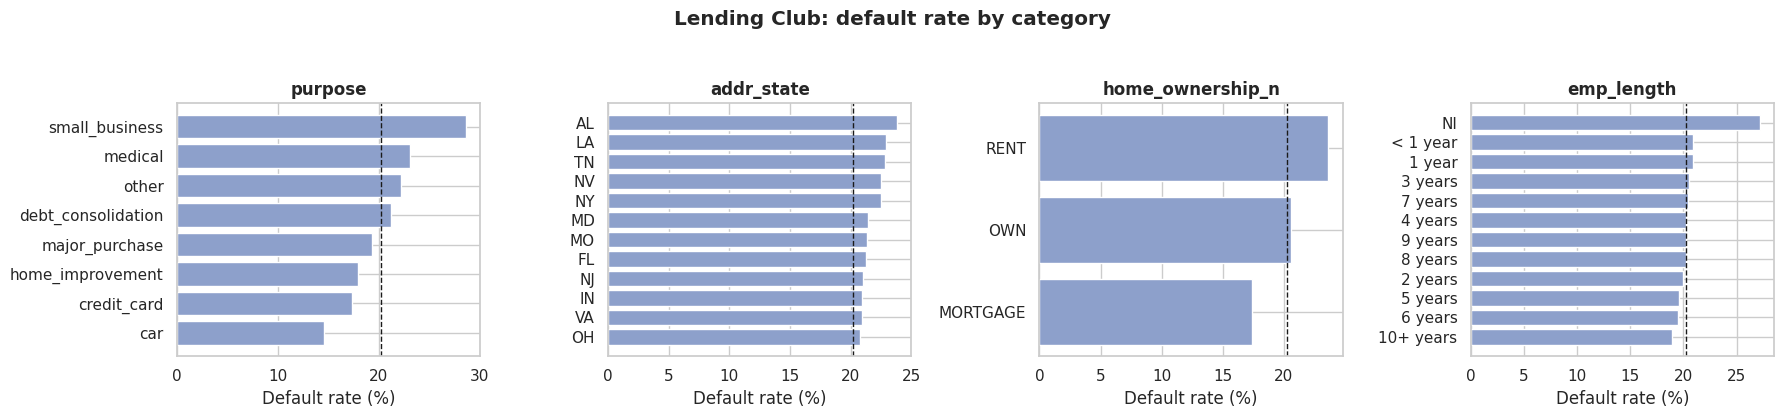

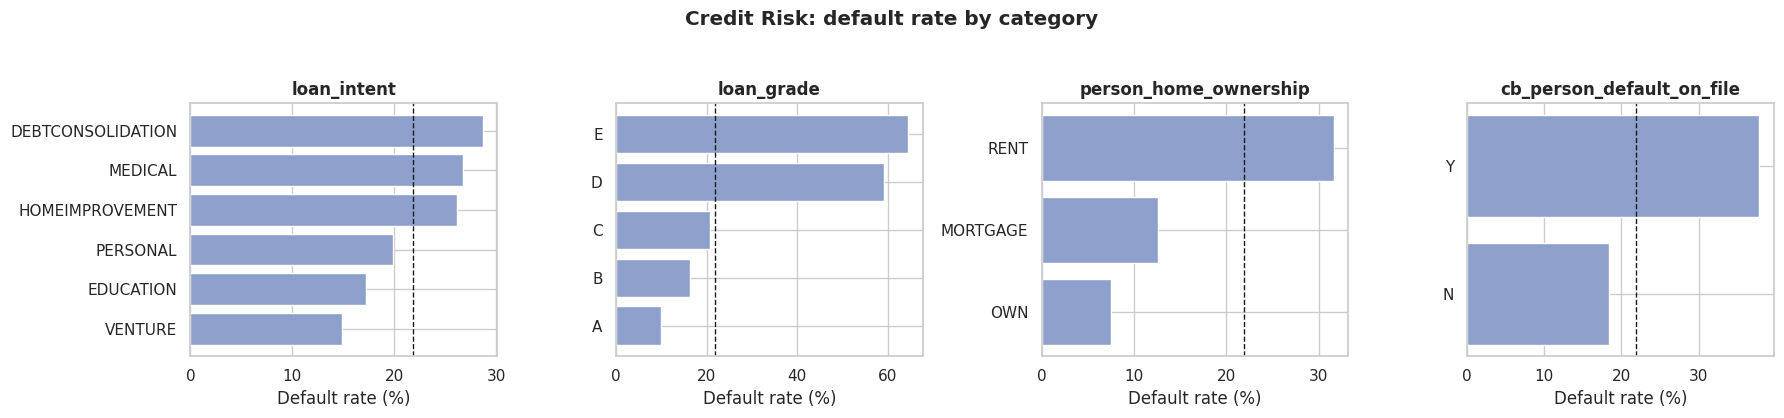

In [14]:
def rate_bar(ax, df, col, target, min_frac=0.01, top=12):
    g = df.groupby(col, observed=True)[target].agg(['mean', 'size'])
    g = g[g['size'] >= max(30, min_frac * len(df))].sort_values('mean', ascending=False).head(top)
    ax.barh(g.index.astype(str)[::-1], g['mean'].values[::-1] * 100, color='#8DA0CB')
    ax.axvline(df[target].mean() * 100, color='k', ls='--', lw=1)
    ax.set_xlabel('Default rate (%)'); ax.set_title(col)

CAT_EDA = {
    'Customer Behavior': ['Profession', 'STATE', 'House_Ownership', 'Car_Ownership'],
    'Lending Club': ['purpose', 'addr_state', 'home_ownership_n', 'emp_length'],
    'Credit Risk': ['loan_intent', 'loan_grade', 'person_home_ownership', 'cb_person_default_on_file'],
}
for n in DS:
    t = TARGET[n]; s = sample_df(clean[n], 200_000)
    fig, axes = plt.subplots(1, 4, figsize=(18, 4))
    for ax, col in zip(axes, CAT_EDA[n]):
        rate_bar(ax, s, col, t)
    fig.suptitle(f'{n}: default rate by category', y=1.04, fontweight='bold')
    save_fig(f'02_eda_categorical_{n.lower().replace(" ", "_")}')

---
# STAGE 3 — TRANSFORMATION
**Goal:** turn the cleaned tables into model-ready inputs *without leaking information from validation/test data into training*.

Order of operations (the order matters for leakage safety):
1. **Feature engineering** — deterministic, row-wise formulas (no statistics learned from data), so they can safely run before splitting.
2. **Splitting** — stratified for Credit Risk, **profile-grouped and stratified** for Customer Behavior, **chronological** for Lending Club.
3. **Learned transformations** (winsorising, imputation, encoding, scaling) — placed *inside* scikit-learn pipelines and fitted on the training split only.

### 3.1 Feature engineering
| Dataset | Engineered feature | Definition |
|---|---|---|
| Customer Behavior | `Income_per_Experience` | Income / (Experience + 1) |
| | `Job_Stability_Ratio` | CURRENT_JOB_YRS / (Experience + 1) |
| | `Career_Start_Age` | Age − Experience |
| Lending Club | `Emp_Years` | `emp_length` text → years (0–10); `NI` → missing |
| | `Loan_to_Income` | loan_amnt / revenue |
| | `Log_Income` | log(1 + revenue) |
| Credit Risk | `Grade_Num` | loan_grade A…G → 1…7 (ordinal) |
| | `Prior_Default` | cb_person_default_on_file Y/N → 1/0 |
| | `Interest_Burden` | loan_amnt × loan_int_rate / 100 / person_income |
| | `CredHist_to_Age`, `Emp_to_Age` | credit-history length and employment length relative to age |

`loan_percent_income` (already in the file) is kept as-is; it is essentially loan_amnt / person_income, so no duplicate ratio is added.

In [15]:
EMP_MAP = {'< 1 year': 0, '1 year': 1, '2 years': 2, '3 years': 3, '4 years': 4, '5 years': 5,
           '6 years': 6, '7 years': 7, '8 years': 8, '9 years': 9, '10+ years': 10}
GRADE_MAP = dict(zip('ABCDEFG', range(1, 8)))

def _clean_inf(d):
    return d.replace([np.inf, -np.inf], np.nan)

def fe_customer(df):
    d = df.copy()
    d['Income_per_Experience'] = d['Income'] / (d['Experience'] + 1)
    d['Job_Stability_Ratio'] = d['CURRENT_JOB_YRS'] / (d['Experience'] + 1)
    d['Career_Start_Age'] = d['Age'] - d['Experience']
    return _clean_inf(d)

def fe_lending(df):
    d = df.copy()
    d['Emp_Years'] = d['emp_length'].astype(object).map(EMP_MAP).astype('float64')   # 'NI' / unknown -> NaN
    rev = d['revenue'].astype('float64')
    d['Loan_to_Income'] = d['loan_amnt'].astype('float64') / rev.where(rev > 0)
    d['Log_Income'] = np.log1p(rev.clip(lower=0))
    return _clean_inf(d)

def fe_credit(df):
    d = df.copy()
    d['Grade_Num'] = d['loan_grade'].map(GRADE_MAP).astype('float64')
    d['Prior_Default'] = (d['cb_person_default_on_file'] == 'Y').astype('float64')
    inc = d['person_income'].astype('float64')
    d['Interest_Burden'] = d['loan_amnt'] * d['loan_int_rate'] / 100.0 / inc.where(inc > 0)
    d['CredHist_to_Age'] = d['cb_person_cred_hist_length'] / d['person_age']
    d['Emp_to_Age'] = d['person_emp_length'] / d['person_age']
    return _clean_inf(d)

FE = {'Customer Behavior': fe_customer, 'Lending Club': fe_lending, 'Credit Risk': fe_credit}

FEATURES = {
    'Customer Behavior': {
        'num': ['Income', 'Age', 'Experience', 'CURRENT_JOB_YRS', 'CURRENT_HOUSE_YRS',
                'Income_per_Experience', 'Job_Stability_Ratio', 'Career_Start_Age'],
        'low': ['Married/Single', 'House_Ownership', 'Car_Ownership'],          # one-hot encoded
        'high': ['Profession', 'CITY', 'STATE']},                               # target encoded
    'Lending Club': {
        'num': ['revenue', 'dti_n', 'loan_amnt', 'fico_n', 'Emp_Years', 'Loan_to_Income', 'Log_Income'],
        'low': ['purpose', 'home_ownership_n'],
        'high': ['addr_state']},
    'Credit Risk': {
        'num': ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate',
                'loan_percent_income', 'cb_person_cred_hist_length', 'Grade_Num', 'Prior_Default',
                'Interest_Burden', 'CredHist_to_Age', 'Emp_to_Age'],
        'low': ['person_home_ownership', 'loan_intent'],
        'high': []},
}
RAW_INPUTS = {   # raw columns a user must supply to score one application (used by the interface in Section 6)
    'Customer Behavior': CUST_FEATS,
    'Lending Club': ['revenue', 'dti_n', 'loan_amnt', 'fico_n', 'emp_length', 'purpose', 'home_ownership_n', 'addr_state'],
    'Credit Risk': ['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent',
                    'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_percent_income',
                    'cb_person_default_on_file', 'cb_person_cred_hist_length'],
}

def prepare_X(name, df, feat=None):
    f = feat or FEATURES[name]
    d = FE[name](df)
    cols = f['num'] + f['low'] + f['high']
    X = d[cols].copy()
    for c in f['num']:
        X[c] = X[c].astype('float64')
    for c in f['low'] + f['high']:
        X[c] = X[c].astype(object)
    return X.reset_index(drop=True)

# Quick sanity check of the engineered features on a few rows
for n in DS:
    X_demo = prepare_X(n, clean[n].head(500))
    eng = [c for c in X_demo.columns if c not in clean[n].columns]
    print(f'{n:18s} engineered: {eng}  -> model matrix {X_demo.shape}')

Customer Behavior  engineered: ['Income_per_Experience', 'Job_Stability_Ratio', 'Career_Start_Age']  -> model matrix (500, 14)
Lending Club       engineered: ['Emp_Years', 'Loan_to_Income', 'Log_Income']  -> model matrix (500, 10)
Credit Risk        engineered: ['Grade_Num', 'Prior_Default', 'Interest_Burden', 'CredHist_to_Age', 'Emp_to_Age']  -> model matrix (500, 14)


### 3.2 Relationships among engineered numeric features
Correlation heatmaps (Pearson, on a ≤100 000-row sample; the target is included as the last column). This is descriptive only.

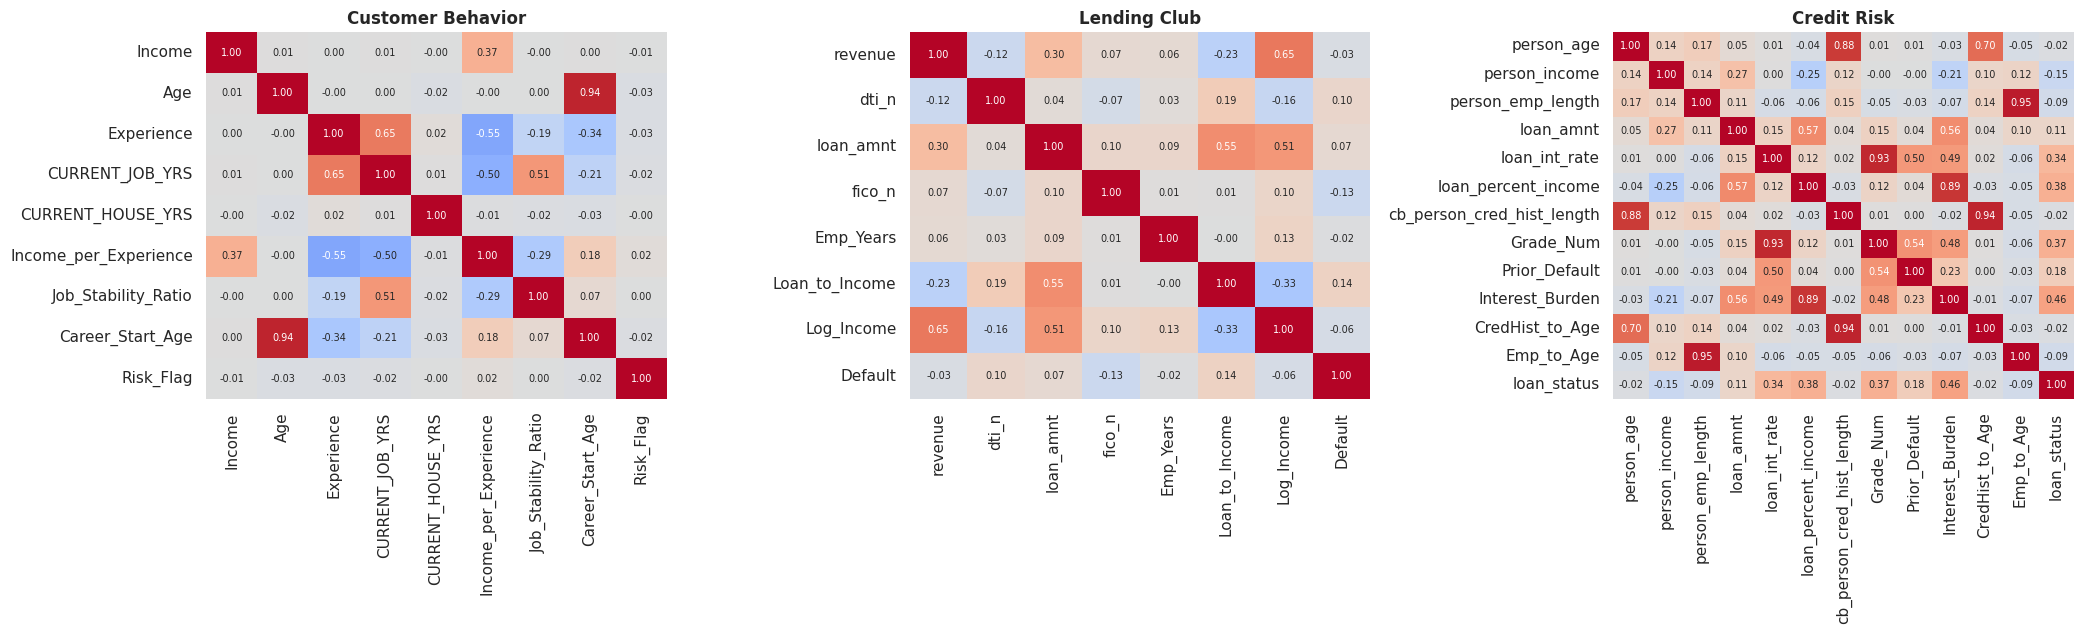

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))
for ax, n in zip(axes, DS):
    s = sample_df(clean[n])
    X = prepare_X(n, s)
    X[TARGET[n]] = s[TARGET[n]].values
    corr = X[FEATURES[n]['num'] + [TARGET[n]]].corr()
    sns.heatmap(corr, cmap='coolwarm', center=0, annot=len(corr) <= 13, fmt='.2f', annot_kws={'size': 7},
                cbar=False, ax=ax)
    ax.set_title(n); ax.tick_params(axis='x', rotation=90)
save_fig('03_correlation_heatmaps')

### 3.3 Leakage-safe train / validation / test splits (60 / 20 / 20)
| Dataset | Strategy | Reason |
|---|---|---|
| Customer Behavior | `StratifiedGroupKFold` on `profile_id` | Identical feature vectors never straddle partitions; class ratio preserved |
| Lending Club | **Chronological**, whole issue-months assigned to one partition | Mimics real deployment (train on the past, predict the future); tests robustness to drift. The training partition is then down-sampled (stratified) to `LC_TRAIN_CAP` rows for Colab speed — validation and test stay complete |
| Credit Risk | Stratified random | Small dataset, no time or group structure |

The **validation** set is used for model selection and threshold tuning; the **test** set is only used for the final report.

In [17]:
DATA = {}

def make_ui_spec(name, raw_train):
    # Defaults / options for the interactive form, derived from TRAINING rows only
    spec = []
    for col in RAW_INPUTS[name]:
        s = raw_train[col]
        if pd.api.types.is_numeric_dtype(s):
            s = s.astype('float64')
            spec.append({'col': col, 'kind': 'num', 'default': float(round(s.median(), 4)),
                         'lo': float(s.quantile(.01)), 'hi': float(s.quantile(.99))})
        else:
            s = s.astype(object).dropna()
            opts = sorted(s.unique().tolist())
            spec.append({'col': col, 'kind': 'cat', 'options': opts, 'default': s.mode().iloc[0]})
    return spec

def register(name, df_tr, df_va, df_te, groups_tr=None, cv_kind=''):
    t = TARGET[name]
    y_tr, y_va, y_te = (d[t].values.astype(int) for d in (df_tr, df_va, df_te))
    DATA[name] = dict(
        X_train=prepare_X(name, df_tr), y_train=y_tr,
        X_val=prepare_X(name, df_va), y_val=y_va,
        X_test=prepare_X(name, df_te), y_test=y_te,
        groups_train=groups_tr, cv_kind=cv_kind,
        spw=float((y_tr == 0).sum() / max((y_tr == 1).sum(), 1)),
        ui_spec=make_ui_spec(name, df_tr),
        raw_test_sample=df_te.sample(n=min(300, len(df_te)), random_state=SEED).reset_index(drop=True))

# ---------------- Customer Behavior: stratified GROUP split --------------------------
c = clean['Customer Behavior']
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = [te for _, te in sgkf.split(c, c['Risk_Flag'].values, c['profile_id'].values)]
te_i, va_i, tr_i = folds[0], folds[1], np.concatenate(folds[2:])
g_tr, g_va, g_te = (set(c['profile_id'].iloc[i]) for i in (tr_i, va_i, te_i))
assert not (g_tr & g_va) and not (g_tr & g_te) and not (g_va & g_te), 'profile overlap between partitions!'
register('Customer Behavior', c.iloc[tr_i], c.iloc[va_i], c.iloc[te_i],
         groups_tr=c['profile_id'].iloc[tr_i].values, cv_kind='group')
print('Customer Behavior: profile-disjoint split verified (no profile appears in two partitions)')

# ---------------- Lending Club: chronological split by issue month -------------------
lc = clean['Lending Club']
per_month = lc.groupby('issue_d').size().sort_index()
cum = per_month.cumsum() / per_month.sum()
cut_tr = cum.index[np.argmax(cum.values >= 0.60)]
cut_va = cum.index[np.argmax(cum.values >= 0.80)]
m_tr, m_va, m_te = lc['issue_d'] <= cut_tr, (lc['issue_d'] > cut_tr) & (lc['issue_d'] <= cut_va), lc['issue_d'] > cut_va
lc_tr, lc_va, lc_te = lc[m_tr], lc[m_va], lc[m_te]
print(f'Lending Club periods  train: {lc_tr.issue_d.min():%b %Y}–{lc_tr.issue_d.max():%b %Y} ({len(lc_tr):,}) | '
      f'val: {lc_va.issue_d.min():%b %Y}–{lc_va.issue_d.max():%b %Y} ({len(lc_va):,}) | '
      f'test: {lc_te.issue_d.min():%b %Y}–{lc_te.issue_d.max():%b %Y} ({len(lc_te):,})')
print('Default rate  train / val / test: '
      f'{lc_tr.Default.mean():.2%} / {lc_va.Default.mean():.2%} / {lc_te.Default.mean():.2%}')
if len(lc_tr) > LC_TRAIN_CAP:
    keep, _ = train_test_split(np.arange(len(lc_tr)), train_size=LC_TRAIN_CAP, stratify=lc_tr['Default'].values,
                               random_state=SEED)
    lc_tr = lc_tr.iloc[np.sort(keep)]          # keep chronological order for time-aware CV
    print(f'Training partition down-sampled (stratified) to {len(lc_tr):,} rows')
register('Lending Club', lc_tr, lc_va, lc_te, cv_kind='time')
del lc_tr, lc_va, lc_te, m_tr, m_va, m_te; gc.collect()

# ---------------- Credit Risk: stratified random split ---------------------------------
cr = clean['Credit Risk']
tv_i, te_i = train_test_split(np.arange(len(cr)), test_size=0.20, stratify=cr['loan_status'], random_state=SEED)
tr_i, va_i = train_test_split(tv_i, test_size=0.25, stratify=cr['loan_status'].iloc[tv_i], random_state=SEED)
register('Credit Risk', cr.iloc[tr_i], cr.iloc[va_i], cr.iloc[te_i], cv_kind='stratified')

split_summary = pd.DataFrame([{
    'Dataset': n, 'Train': len(d['y_train']), 'Validation': len(d['y_val']), 'Test': len(d['y_test']),
    'Default % (train / val / test)': f"{d['y_train'].mean():.1%} / {d['y_val'].mean():.1%} / {d['y_test'].mean():.1%}",
    'Features': d['X_train'].shape[1], 'scale_pos_weight': round(d['spw'], 2)} for n, d in DATA.items()])
display(split_summary)

Customer Behavior: profile-disjoint split verified (no profile appears in two partitions)
Lending Club periods  train: Jun 2007–Nov 2015 (790,346) | val: Dec 2015–Aug 2016 (257,840) | test: Sep 2016–Dec 2017 (243,335)
Default rate  train / val / test: 18.34% / 22.68% / 23.43%
Training partition down-sampled (stratified) to 300,000 rows


,Dataset,Train,Validation,Test,Default % (train / val / test),Features,scale_pos_weight
0,Customer Behavior,145687,52006,54307,12.6% / 11.7% / 12.1%,14,6.94
1,Lending Club,300000,257840,243335,18.3% / 22.7% / 23.4%,10,4.45
2,Credit Risk,19449,6483,6484,21.9% / 21.9% / 21.9%,14,3.57


### 3.4 Encoding, outlier clipping, imputation and scaling — inside pipelines
| Step | Applies to | Fitted on |
|---|---|---|
| `QuantileClipper` (0.1 % – 99.9 %) | numeric columns | training split only |
| Median imputation **+ missing-indicator columns** | numeric columns | training split only |
| `StandardScaler` | numeric columns | training split only |
| Most-frequent imputation → **One-Hot** (rare levels pooled) | low-cardinality categoricals | training split only |
| Most-frequent imputation → **Target encoding** (smoothed, 5-fold cross-fitted inside `fit`) | high-cardinality categoricals (`Profession`, `CITY`, `STATE`, `addr_state`) | training split only |

Target encoding is cross-fitted by scikit-learn during `fit`, so the encoded training values never use their own label; validation/test rows use encodings learned from the full training split. Tree models are invariant to scaling, so the common preprocessing is harmless for them and keeps the comparison between models controlled.

In [18]:
class QuantileClipper(OneToOneFeatureMixin, TransformerMixin, BaseEstimator):
    # Winsorises each column at quantiles learned during fit (NaN-safe).
    def __init__(self, lower=0.001, upper=0.999):
        self.lower = lower
        self.upper = upper
    def fit(self, X, y=None):
        A = np.asarray(X, dtype='float64')
        self.lo_ = np.nanquantile(A, self.lower, axis=0)
        self.hi_ = np.nanquantile(A, self.upper, axis=0)
        self.n_features_in_ = A.shape[1]
        if hasattr(X, 'columns'):
            self.feature_names_in_ = np.asarray(X.columns, dtype=object)
        return self
    def transform(self, X):
        return np.clip(np.asarray(X, dtype='float64'), self.lo_, self.hi_)

def build_preprocessor(feat):
    parts = []
    parts.append(('num', Pipeline([
        ('clip', QuantileClipper(0.001, 0.999)),
        ('impute', SimpleImputer(strategy='median', add_indicator=True)),
        ('scale', StandardScaler())]), feat['num']))
    if feat['low']:
        parts.append(('low', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('onehot', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=0.005,
                                     sparse_output=False))]), feat['low']))
    if feat['high']:
        parts.append(('high', Pipeline([
            ('impute', SimpleImputer(strategy='most_frequent')),
            ('target_enc', TargetEncoder(smooth='auto', cv=5, shuffle=True, random_state=SEED))]), feat['high']))
    return ColumnTransformer(parts, remainder='drop', verbose_feature_names_out=True)

def short_names(names):
    return [re.sub(r'^(num|low|high)__', '', str(n)) for n in names]

# Demonstrate the fitted transformation on one dataset (training data only)
demo_prep = build_preprocessor(FEATURES['Credit Risk']).fit(DATA['Credit Risk']['X_train'], DATA['Credit Risk']['y_train'])
Z = demo_prep.transform(DATA['Credit Risk']['X_val'])
print('Credit Risk — validation matrix after transformation:', Z.shape, '| NaNs:', int(np.isnan(Z).sum()))
print('Example output columns:', short_names(demo_prep.get_feature_names_out())[:14], '...')
del demo_prep, Z

Credit Risk — validation matrix after transformation: (6483, 28) | NaNs: 0
Example output columns: ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'Grade_Num', 'Prior_Default', 'Interest_Burden', 'CredHist_to_Age', 'Emp_to_Age', 'missingindicator_person_age', 'missingindicator_person_emp_length'] ...


---
# STAGE 4 — DATA MINING
**Goal:** fit and tune the three model families on each dataset.

* **Logistic Regression** — interpretable linear baseline (`class_weight='balanced'`).
* **Random Forest** — bagged trees (`class_weight='balanced_subsample'`).
* **XGBoost** — gradient-boosted trees (`scale_pos_weight` = negatives / positives of the training split).

Protocol: (1) fit a sensible **baseline** configuration of each model; (2) run a **randomized hyper-parameter search** (scoring = PR-AUC / average precision, which is appropriate for imbalanced data) on a stratified subsample of the training split with **leakage-aware CV** — group-aware for Customer Behavior, forward-chaining time splits for Lending Club, stratified k-fold for Credit Risk; (3) **refit the best configuration on the full training split**.

In [19]:
def make_model(name, key):
    d = DATA[name]
    if key == 'Logistic Regression':
        return LogisticRegression(C=1.0, class_weight='balanced', max_iter=2000, random_state=SEED)
    if key == 'Random Forest':
        return RandomForestClassifier(n_estimators=RF_TREES[0], max_depth=12, min_samples_leaf=10, max_features='sqrt',
                                      class_weight='balanced_subsample', n_jobs=-1, random_state=SEED,
                                      max_samples=(0.5 if len(d['y_train']) > 200_000 else None))
    if key == 'XGBoost':
        return XGBClassifier(n_estimators=200, max_depth=4, learning_rate=0.1, subsample=0.8, colsample_bytree=0.8,
                             scale_pos_weight=d['spw'], tree_method='hist', eval_metric='aucpr',
                             n_jobs=-1, random_state=SEED, verbosity=0)
    raise ValueError(key)

def make_pipeline(name, key, feat=None):
    return Pipeline([('prep', build_preprocessor(feat or FEATURES[name])), ('model', make_model(name, key))])

PARAM_DISTS = {
    'Logistic Regression': {'model__C': [0.003, 0.01, 0.03, 0.1, 0.3, 1, 3, 10]},
    'Random Forest': {'model__n_estimators': RF_TREES, 'model__max_depth': [6, 10, 14, 18],
                      'model__min_samples_leaf': [10, 25, 50], 'model__max_features': ['sqrt', 0.3, 0.5]},
    'XGBoost': {'model__n_estimators': [150, 250, 400], 'model__max_depth': [3, 4, 5, 6, 8],
                'model__learning_rate': [0.03, 0.05, 0.1], 'model__subsample': [0.7, 0.85, 1.0],
                'model__colsample_bytree': [0.6, 0.8, 1.0], 'model__min_child_weight': [1, 5, 10],
                'model__reg_lambda': [1, 5, 10]},
}

def metric_row(y, p, thr=0.5):
    yhat = (p >= thr).astype(int)
    return {'Accuracy': accuracy_score(y, yhat), 'Precision': precision_score(y, yhat, zero_division=0),
            'Recall': recall_score(y, yhat, zero_division=0), 'F1': f1_score(y, yhat, zero_division=0),
            'ROC-AUC': roc_auc_score(y, p), 'PR-AUC': average_precision_score(y, p)}

def best_f1_threshold(y, p):
    prec, rec, thr = precision_recall_curve(y, p)
    f1 = 2 * prec[:-1] * rec[:-1] / np.maximum(prec[:-1] + rec[:-1], 1e-12)
    i = int(np.nanargmax(f1))
    return float(thr[i]), float(f1[i])

print('Helpers ready.')

Helpers ready.


### 4.1 Baseline models (default-style configuration, scored on the validation set)

In [20]:
BASE_ROWS, BASE_VAL_P = [], {n: {} for n in DS}
for name in DS:
    d = DATA[name]
    for key in MODEL_KEYS:
        t0 = time.time()
        pipe = make_pipeline(name, key).fit(d['X_train'], d['y_train'])
        p = pipe.predict_proba(d['X_val'])[:, 1]
        BASE_VAL_P[name][key] = p
        BASE_ROWS.append({'Dataset': name, 'Model': key, **metric_row(d['y_val'], p, 0.5), 'Fit time (s)': time.time() - t0})
        print(f'  {name:18s} {key:20s} val PR-AUC={BASE_ROWS[-1]["PR-AUC"]:.4f}  ({BASE_ROWS[-1]["Fit time (s)"]:.0f}s)')
        del pipe; gc.collect()
baseline_val = pd.DataFrame(BASE_ROWS)
display(baseline_val.round(4))

  Customer Behavior  Logistic Regression  val PR-AUC=0.1214  (5s)
  Customer Behavior  Random Forest        val PR-AUC=0.1196  (23s)
  Customer Behavior  XGBoost              val PR-AUC=0.1307  (5s)
  Lending Club       Logistic Regression  val PR-AUC=0.3585  (6s)
  Lending Club       Random Forest        val PR-AUC=0.3561  (33s)
  Lending Club       XGBoost              val PR-AUC=0.3617  (8s)
  Credit Risk        Logistic Regression  val PR-AUC=0.7188  (0s)
  Credit Risk        Random Forest        val PR-AUC=0.8759  (4s)
  Credit Risk        XGBoost              val PR-AUC=0.8991  (1s)


,Dataset,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC,Fit time (s)
0,Customer Behavior,Logistic Regression,0.5792,0.1171,0.3974,0.1809,0.5087,0.1214,4.5763
1,Customer Behavior,Random Forest,0.7075,0.1155,0.2257,0.1528,0.5075,0.1196,23.2693
2,Customer Behavior,XGBoost,0.6227,0.1229,0.3628,0.1836,0.5178,0.1307,4.7582
3,Lending Club,Logistic Regression,0.6111,0.3196,0.6332,0.4248,0.6672,0.3585,5.6852
4,Lending Club,Random Forest,0.6511,0.3357,0.5501,0.4170,0.6657,0.3561,33.1801
5,Lending Club,XGBoost,0.6158,0.3222,0.6288,0.4261,0.6694,0.3617,7.9493
6,Credit Risk,Logistic Regression,0.7928,0.5169,0.8068,0.6301,0.8730,0.7188,0.4395
7,Credit Risk,Random Forest,0.9091,0.8100,0.7638,0.7862,0.9264,0.8759,3.9671
8,Credit Risk,XGBoost,0.9090,0.7855,0.8032,0.7943,0.9445,0.8991,0.7506


### 4.2 Hyper-parameter tuning (randomized search, leakage-aware CV)
The search runs on a stratified subsample (`TUNE_CAP` rows) of the **training** split only; the validation and test sets are never touched here.

In [21]:
def tuning_subset(name):
    d = DATA[name]; n = len(d['y_train'])
    if n <= TUNE_CAP:
        return np.arange(n)
    idx, _ = train_test_split(np.arange(n), train_size=TUNE_CAP, stratify=d['y_train'], random_state=SEED)
    return np.sort(idx)                      # sorted -> preserves chronological order for Lending Club

def make_cv(kind):
    if kind == 'group':
        return StratifiedGroupKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
    if kind == 'time':
        return TimeSeriesSplit(n_splits=CV_FOLDS)
    return StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)

def grid_size(dist):
    s = 1
    for v in dist.values():
        s *= len(v)
    return s

BEST_PARAMS, TUNE_ROWS, CV_TABLES = {n: {} for n in DS}, [], {}
for name in DS:
    d = DATA[name]; idx = tuning_subset(name)
    Xt, yt = d['X_train'].iloc[idx], d['y_train'][idx]
    gt = d['groups_train'][idx] if d['groups_train'] is not None else None
    for key in MODEL_KEYS:
        t0 = time.time()
        dist = PARAM_DISTS[key]
        search = RandomizedSearchCV(make_pipeline(name, key), dist, n_iter=min(N_ITER[key], grid_size(dist)),
                                    scoring='average_precision', cv=make_cv(d['cv_kind']), random_state=SEED,
                                    n_jobs=1, refit=False, error_score='raise')
        if gt is not None:
            search.fit(Xt, yt, groups=gt)
        else:
            search.fit(Xt, yt)
        BEST_PARAMS[name][key] = search.best_params_
        res = pd.DataFrame(search.cv_results_).sort_values('rank_test_score')
        CV_TABLES[(name, key)] = res[['rank_test_score', 'mean_test_score', 'std_test_score', 'params']]
        TUNE_ROWS.append({'Dataset': name, 'Model': key, 'CV scheme': d['cv_kind'], 'Tuning rows': len(idx),
                          'Candidates': len(res), 'Best CV PR-AUC': search.best_score_,
                          'Best parameters': {k.replace('model__', ''): v for k, v in search.best_params_.items()},
                          'Search time (s)': round(time.time() - t0)})
        print(f'  {name:18s} {key:20s} best CV PR-AUC={search.best_score_:.4f}  ({time.time()-t0:.0f}s)')
        gc.collect()
tuning_summary = pd.DataFrame(TUNE_ROWS)
pd.set_option('display.max_colwidth', 160)
display(tuning_summary)

  Customer Behavior  Logistic Regression  best CV PR-AUC=0.1420  (27s)
  Customer Behavior  Random Forest        best CV PR-AUC=0.1351  (203s)
  Customer Behavior  XGBoost              best CV PR-AUC=0.1366  (56s)
  Lending Club       Logistic Regression  best CV PR-AUC=0.2755  (15s)
  Lending Club       Random Forest        best CV PR-AUC=0.2733  (95s)
  Lending Club       XGBoost              best CV PR-AUC=0.2781  (47s)
  Credit Risk        Logistic Regression  best CV PR-AUC=0.6981  (4s)
  Credit Risk        Random Forest        best CV PR-AUC=0.8708  (80s)
  Credit Risk        XGBoost              best CV PR-AUC=0.8951  (29s)


,Dataset,Model,CV scheme,Tuning rows,Candidates,Best CV PR-AUC,Best parameters,Search time (s)
0,Customer Behavior,Logistic Regression,group,50000,8,0.142034,{'C': 0.003},27
1,Customer Behavior,Random Forest,group,50000,8,0.135094,"{'n_estimators': 150, 'min_samples_leaf': 25, 'max_features': 'sqrt', 'max_depth': 6}",203
2,Customer Behavior,XGBoost,group,50000,10,0.136622,"{'subsample': 0.85, 'reg_lambda': 10, 'n_estimators': 400, 'min_child_weight': 10, 'max_depth': 3, 'learning_rate': 0.03, 'colsample_bytree': 0.8}",56
3,Lending Club,Logistic Regression,time,50000,8,0.275523,{'C': 3},15
4,Lending Club,Random Forest,time,50000,8,0.273292,"{'n_estimators': 150, 'min_samples_leaf': 10, 'max_features': 0.3, 'max_depth': 6}",95
5,Lending Club,XGBoost,time,50000,10,0.278094,"{'subsample': 0.85, 'reg_lambda': 10, 'n_estimators': 150, 'min_child_weight': 10, 'max_depth': 3, 'learning_rate': 0.05, 'colsample_bytree': 0.6}",47
6,Credit Risk,Logistic Regression,stratified,19449,8,0.698130,{'C': 0.3},4
7,Credit Risk,Random Forest,stratified,19449,8,0.870789,"{'n_estimators': 100, 'min_samples_leaf': 10, 'max_features': 0.5, 'max_depth': 10}",80
8,Credit Risk,XGBoost,stratified,19449,10,0.895129,"{'subsample': 1.0, 'reg_lambda': 5, 'n_estimators': 400, 'min_child_weight': 10, 'max_depth': 6, 'learning_rate': 0.1, 'colsample_bytree': 0.6}",29


### 4.3 Final training of the nine tuned models on the full training split

In [22]:
MODELS, VAL_P, FIT_TIME = {n: {} for n in DS}, {n: {} for n in DS}, {}
for name in DS:
    d = DATA[name]
    for key in MODEL_KEYS:
        t0 = time.time()
        pipe = make_pipeline(name, key).set_params(**BEST_PARAMS[name][key])
        pipe.fit(d['X_train'], d['y_train'])
        MODELS[name][key] = pipe
        VAL_P[name][key] = pipe.predict_proba(d['X_val'])[:, 1]
        FIT_TIME[(name, key)] = time.time() - t0
        print(f'  {name:18s} {key:20s} fitted on {len(d["y_train"]):,} rows ({FIT_TIME[(name, key)]:.0f}s)')
        gc.collect()
print('\n9 tuned models ready.')

  Customer Behavior  Logistic Regression  fitted on 145,687 rows (3s)
  Customer Behavior  Random Forest        fitted on 145,687 rows (23s)
  Customer Behavior  XGBoost              fitted on 145,687 rows (7s)
  Lending Club       Logistic Regression  fitted on 300,000 rows (6s)
  Lending Club       Random Forest        fitted on 300,000 rows (41s)
  Lending Club       XGBoost              fitted on 300,000 rows (8s)
  Credit Risk        Logistic Regression  fitted on 19,449 rows (0s)
  Credit Risk        Random Forest        fitted on 19,449 rows (4s)
  Credit Risk        XGBoost              fitted on 19,449 rows (1s)

9 tuned models ready.


### 4.4 Feature importance for all nine models
* Logistic Regression — absolute standardised coefficients
* Random Forest / XGBoost — impurity-based (gain) importance

Impurity importance can favour high-cardinality or continuous features; it is complemented by permutation importance and SHAP in Section 5.

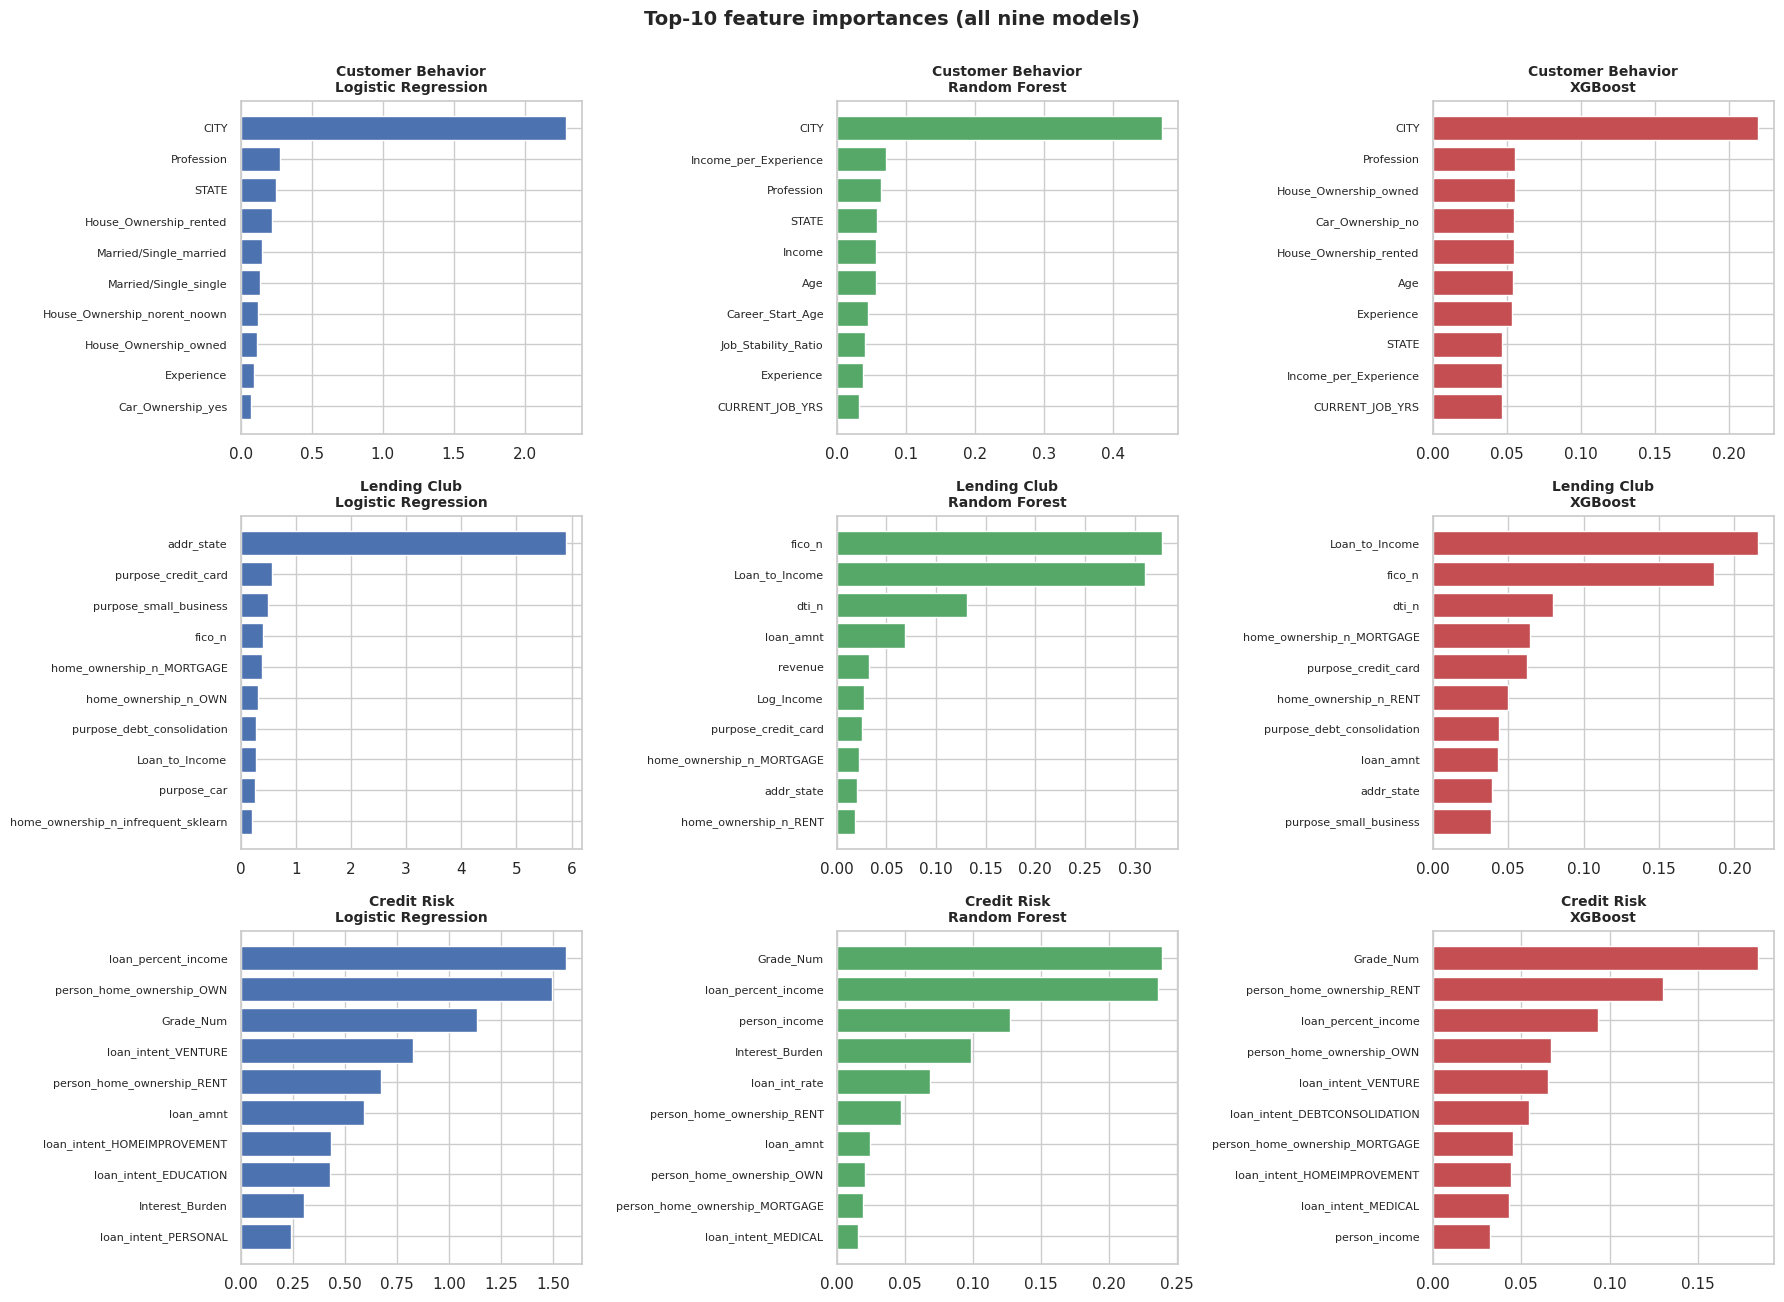

In [23]:
def model_importance(pipe, key):
    names = short_names(pipe.named_steps['prep'].get_feature_names_out())
    m = pipe.named_steps['model']
    vals = np.abs(m.coef_[0]) if key == 'Logistic Regression' else np.asarray(m.feature_importances_, dtype=float)
    return pd.Series(vals, index=names).sort_values(ascending=False)

fig, axes = plt.subplots(3, 3, figsize=(18, 13))
IMPORTANCE = {}
for i, name in enumerate(DS):
    for j, key in enumerate(MODEL_KEYS):
        imp = model_importance(MODELS[name][key], key)
        IMPORTANCE[(name, key)] = imp
        top = imp.head(10)[::-1]
        axes[i, j].barh(top.index, top.values, color=MODEL_COLORS[key])
        axes[i, j].set_title(f'{name}\n{key}', fontsize=10)
        axes[i, j].tick_params(axis='y', labelsize=8)
fig.suptitle('Top-10 feature importances (all nine models)', fontsize=14, fontweight='bold', y=1.0)
save_fig('04_feature_importance_all_models')

### 4.5 Class-imbalance handling: does weighting help?
XGBoost is re-fitted with **no** class weighting (`scale_pos_weight = 1`, same tuned parameters) and compared with the weighted model already trained. Threshold-independent metrics (ROC-AUC, PR-AUC) are expected to move little; the point of weighting is mainly to shift probabilities so that recall of the minority class at the default 0.5 cut-off is not close to zero. Scores are on the **validation** set.

In [24]:
imb_rows = []
for name in DS:
    d = DATA[name]
    unw = make_pipeline(name, 'XGBoost').set_params(**BEST_PARAMS[name]['XGBoost'])
    unw.set_params(model__scale_pos_weight=1.0).fit(d['X_train'], d['y_train'])
    p_unw = unw.predict_proba(d['X_val'])[:, 1]
    for label, p in [('No weighting (spw = 1)', p_unw), (f'Weighted (spw = {d["spw"]:.2f})', VAL_P[name]['XGBoost'])]:
        r = metric_row(d['y_val'], p, 0.5)
        thr_f1, f1_best = best_f1_threshold(d['y_val'], p)
        imb_rows.append({'Dataset': name, 'XGBoost variant': label, 'Precision@0.5': r['Precision'],
                         'Recall@0.5': r['Recall'], 'F1@0.5': r['F1'], 'ROC-AUC': r['ROC-AUC'],
                         'PR-AUC': r['PR-AUC'], 'Best-F1 threshold': thr_f1, 'Best F1': f1_best})
    del unw; gc.collect()
imbalance_compare = pd.DataFrame(imb_rows)
display(imbalance_compare.round(4))

,Dataset,XGBoost variant,Precision@0.5,Recall@0.5,F1@0.5,ROC-AUC,PR-AUC,Best-F1 threshold,Best F1
0,Customer Behavior,No weighting (spw = 1),0.0000,0.0000,0.0000,0.5174,0.1273,0.0322,0.2110
1,Customer Behavior,Weighted (spw = 6.94),0.1174,0.4253,0.1840,0.5109,0.1264,0.1668,0.2105
2,Lending Club,No weighting (spw = 1),0.5775,0.0007,0.0014,0.6688,0.3617,0.1670,0.4271
3,Lending Club,Weighted (spw = 4.45),0.3226,0.6235,0.4252,0.6688,0.3614,0.4825,0.4269
4,Credit Risk,No weighting (spw = 1),0.9643,0.7419,0.8386,0.9479,0.9063,0.5330,0.8421
5,Credit Risk,Weighted (spw = 3.57),0.8337,0.8096,0.8215,0.9485,0.9075,0.7278,0.8427


---
# STAGE 5 — EVALUATION AND INTERPRETATION
**Goal:** judge the nine models fairly, interpret what they learned, and test whether the results can be trusted.

Protocol (the test set is touched **only** from 5.3 onward and never used to choose anything):
1. **Validation set** → compare baseline vs tuned models, pick the best model per dataset by **PR-AUC**, and tune each model's decision threshold (maximum F1).
2. **Test set** → report all nine models once, at their validation-chosen thresholds (and, for reference, at 0.5).

### 5.1 Validation: baseline vs tuned

,Dataset,Model,ROC-AUC (baseline),PR-AUC (baseline),ROC-AUC (tuned),PR-AUC (tuned),PR-AUC change
0,Customer Behavior,Logistic Regression,0.5087,0.1214,0.5286,0.1253,0.0039
1,Customer Behavior,Random Forest,0.5075,0.1196,0.5118,0.1240,0.0045
2,Customer Behavior,XGBoost,0.5178,0.1307,0.5109,0.1264,-0.0043
3,Lending Club,Logistic Regression,0.6672,0.3585,0.6672,0.3584,-0.0000
4,Lending Club,Random Forest,0.6657,0.3561,0.6608,0.3522,-0.0039
5,Lending Club,XGBoost,0.6694,0.3617,0.6688,0.3614,-0.0002
6,Credit Risk,Logistic Regression,0.8730,0.7188,0.8730,0.7187,-0.0000
7,Credit Risk,Random Forest,0.9264,0.8759,0.9306,0.8833,0.0074
8,Credit Risk,XGBoost,0.9445,0.8991,0.9485,0.9075,0.0084


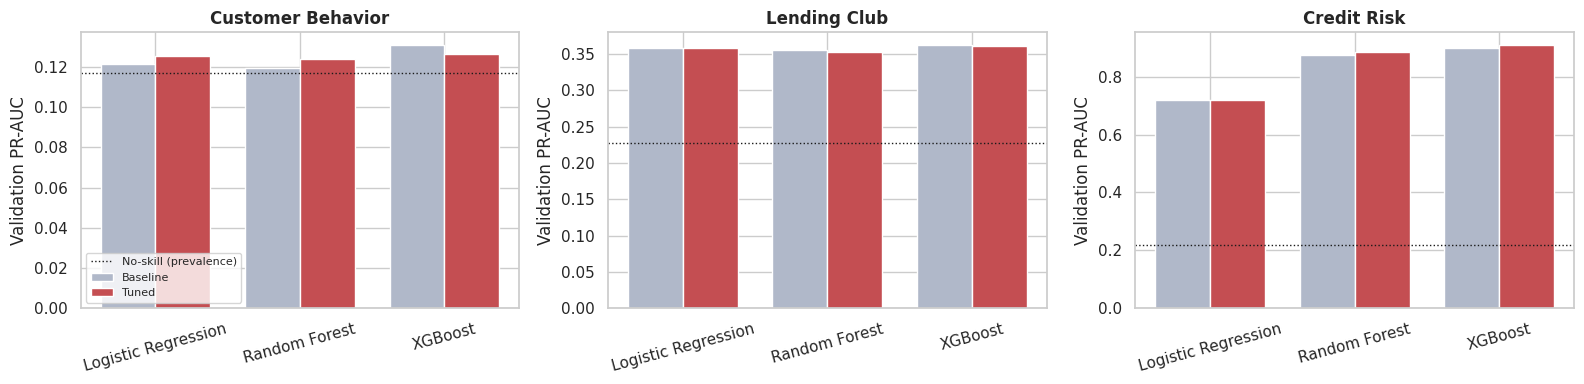

In [25]:
tuned_rows = []
for name in DS:
    for key in MODEL_KEYS:
        tuned_rows.append({'Dataset': name, 'Model': key, **metric_row(DATA[name]['y_val'], VAL_P[name][key], 0.5)})
tuned_val = pd.DataFrame(tuned_rows)

cmp = baseline_val[['Dataset', 'Model', 'ROC-AUC', 'PR-AUC']].merge(
    tuned_val[['Dataset', 'Model', 'ROC-AUC', 'PR-AUC']], on=['Dataset', 'Model'], suffixes=(' (baseline)', ' (tuned)'))
cmp['PR-AUC change'] = cmp['PR-AUC (tuned)'] - cmp['PR-AUC (baseline)']
display(cmp.round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, name in zip(axes, DS):
    sub = cmp[cmp['Dataset'] == name]
    x = np.arange(len(sub)); w = 0.38
    ax.bar(x - w/2, sub['PR-AUC (baseline)'], w, label='Baseline', color='#B0B8C9')
    ax.bar(x + w/2, sub['PR-AUC (tuned)'], w, label='Tuned', color='#C44E52')
    ax.axhline(DATA[name]['y_val'].mean(), color='k', ls=':', lw=1, label='No-skill (prevalence)')
    ax.set_xticks(x); ax.set_xticklabels(sub['Model'], rotation=15); ax.set_title(name); ax.set_ylabel('Validation PR-AUC')
axes[0].legend(fontsize=8)
save_fig('05_validation_baseline_vs_tuned')

In [26]:
# Best model per dataset by validation PR-AUC, and F1-optimal threshold per model (validation only)
BEST, THR = {}, {n: {} for n in DS}
sel_rows = []
for name in DS:
    y = DATA[name]['y_val']
    for key in MODEL_KEYS:
        THR[name][key], f1v = best_f1_threshold(y, VAL_P[name][key])
    BEST[name] = max(MODEL_KEYS, key=lambda k: average_precision_score(y, VAL_P[name][k]))
    sel_rows.append({'Dataset': name, 'Selected model (max validation PR-AUC)': BEST[name],
                     'Validation PR-AUC': average_precision_score(y, VAL_P[name][BEST[name]]),
                     'Validation ROC-AUC': roc_auc_score(y, VAL_P[name][BEST[name]]),
                     'F1-optimal threshold': THR[name][BEST[name]], 'Prevalence (no-skill PR-AUC)': y.mean()})
selection_df = pd.DataFrame(sel_rows)
display(selection_df.round(4))

,Dataset,Selected model (max validation PR-AUC),Validation PR-AUC,Validation ROC-AUC,F1-optimal threshold,Prevalence (no-skill PR-AUC)
0,Customer Behavior,XGBoost,0.1264,0.5109,0.1668,0.1169
1,Lending Club,XGBoost,0.3614,0.6688,0.4825,0.2268
2,Credit Risk,XGBoost,0.9075,0.9485,0.7278,0.2187


### 5.2 Test-set evaluation of all nine models
Probabilities are computed once on the held-out test partitions. The main table uses each model's **validation-tuned threshold**; the second uses the plain **0.5** cut-off.

TEST results at validation-tuned thresholds (★ = model chosen on validation PR-AUC)


,Dataset,Model,Selected,Threshold,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Customer Behavior,Logistic Regression,,0.4586,0.3337,0.1302,0.7947,0.2237,0.5476,0.1353
1,Customer Behavior,Random Forest,,0.3760,0.2742,0.1241,0.8262,0.2157,0.5188,0.1294
2,Customer Behavior,XGBoost,★,0.1668,0.1296,0.1199,0.9790,0.2137,0.5226,0.1340
3,Lending Club,Logistic Regression,,0.4890,0.6257,0.3364,0.6147,0.4349,0.6722,0.3743
4,Lending Club,Random Forest,,0.4646,0.5916,0.3209,0.6657,0.4330,0.6646,0.3639
5,Lending Club,XGBoost,★,0.4825,0.6236,0.3359,0.6209,0.4359,0.6728,0.3743
6,Credit Risk,Logistic Regression,,0.6902,0.8512,0.6707,0.6276,0.6485,0.8642,0.7031
7,Credit Risk,Random Forest,,0.5856,0.9318,0.9621,0.7165,0.8213,0.9248,0.8773
8,Credit Risk,XGBoost,★,0.7278,0.9377,0.9703,0.7377,0.8381,0.9456,0.9037


TEST results at threshold = 0.5


,Dataset,Model,Accuracy,Precision,Recall,F1,ROC-AUC,PR-AUC
0,Customer Behavior,Logistic Regression,0.5508,0.1371,0.5135,0.2164,0.5476,0.1353
1,Customer Behavior,Random Forest,0.5683,0.1287,0.4461,0.1998,0.5188,0.1294
2,Customer Behavior,XGBoost,0.5714,0.1305,0.4501,0.2024,0.5226,0.1340
3,Lending Club,Logistic Regression,0.6400,0.3429,0.5858,0.4326,0.6722,0.3743
4,Lending Club,Random Forest,0.6580,0.3481,0.5272,0.4194,0.6646,0.3639
5,Lending Club,XGBoost,0.6476,0.3465,0.5695,0.4309,0.6728,0.3743
6,Credit Risk,Logistic Regression,0.7878,0.5097,0.7779,0.6159,0.8642,0.7031
7,Credit Risk,Random Forest,0.9257,0.9007,0.7419,0.8136,0.9248,0.8773
8,Credit Risk,XGBoost,0.9238,0.8484,0.7934,0.8200,0.9456,0.9037


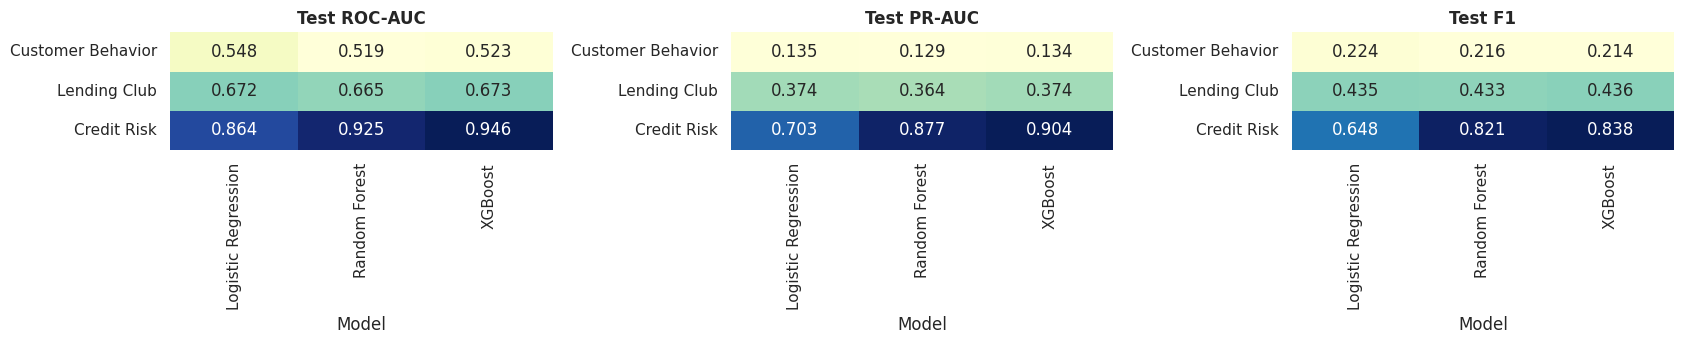

In [27]:
TEST_P = {n: {k: MODELS[n][k].predict_proba(DATA[n]['X_test'])[:, 1] for k in MODEL_KEYS} for n in DS}

main_rows, ref_rows = [], []
for name in DS:
    y = DATA[name]['y_test']
    for key in MODEL_KEYS:
        main_rows.append({'Dataset': name, 'Model': key, 'Selected': '★' if BEST[name] == key else '',
                          'Threshold': THR[name][key], **metric_row(y, TEST_P[name][key], THR[name][key])})
        ref_rows.append({'Dataset': name, 'Model': key, **metric_row(y, TEST_P[name][key], 0.5)})
test_main = pd.DataFrame(main_rows)
test_ref = pd.DataFrame(ref_rows)
print('TEST results at validation-tuned thresholds (★ = model chosen on validation PR-AUC)')
display(test_main.round(4))
print('TEST results at threshold = 0.5')
display(test_ref.round(4))

# Heat-map style comparison of the nine models
fig, axes = plt.subplots(1, 3, figsize=(17, 3.6))
for ax, metric in zip(axes, ['ROC-AUC', 'PR-AUC', 'F1']):
    piv = test_main.pivot(index='Dataset', columns='Model', values=metric).loc[DS, MODEL_KEYS]
    sns.heatmap(piv, annot=True, fmt='.3f', cmap='YlGnBu', cbar=False, ax=ax)
    ax.set_title(f'Test {metric}'); ax.set_ylabel('')
save_fig('05_test_metric_heatmaps')

### 5.3 Confusion matrices (test set, validation-tuned thresholds)

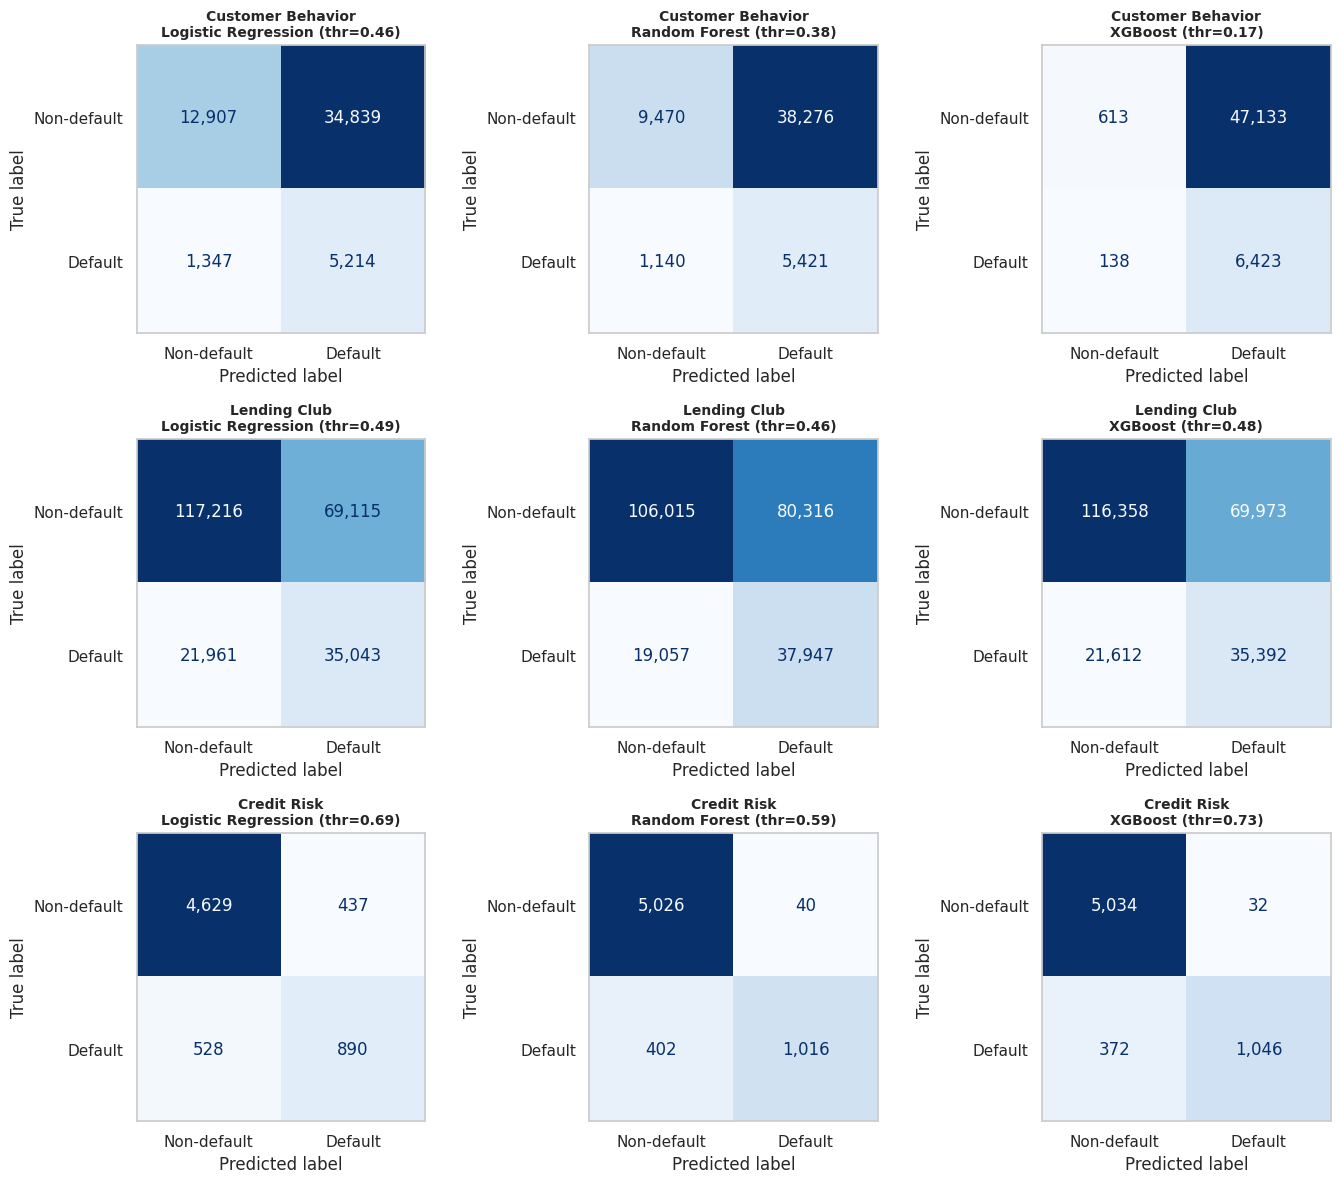

In [28]:
fig, axes = plt.subplots(3, 3, figsize=(14, 12))
for i, name in enumerate(DS):
    for j, key in enumerate(MODEL_KEYS):
        y = DATA[name]['y_test']; pred = (TEST_P[name][key] >= THR[name][key]).astype(int)
        cm = confusion_matrix(y, pred, labels=[0, 1])
        ConfusionMatrixDisplay(cm, display_labels=['Non-default', 'Default']).plot(
            ax=axes[i, j], cmap='Blues', colorbar=False, values_format=',d')
        axes[i, j].set_title(f'{name}\n{key} (thr={THR[name][key]:.2f})', fontsize=10)
        axes[i, j].grid(False)
save_fig('05_confusion_matrices')

### 5.4 ROC and precision-recall curves (test set)
The dotted line in the PR panels is the no-skill baseline (= default prevalence of that test set).

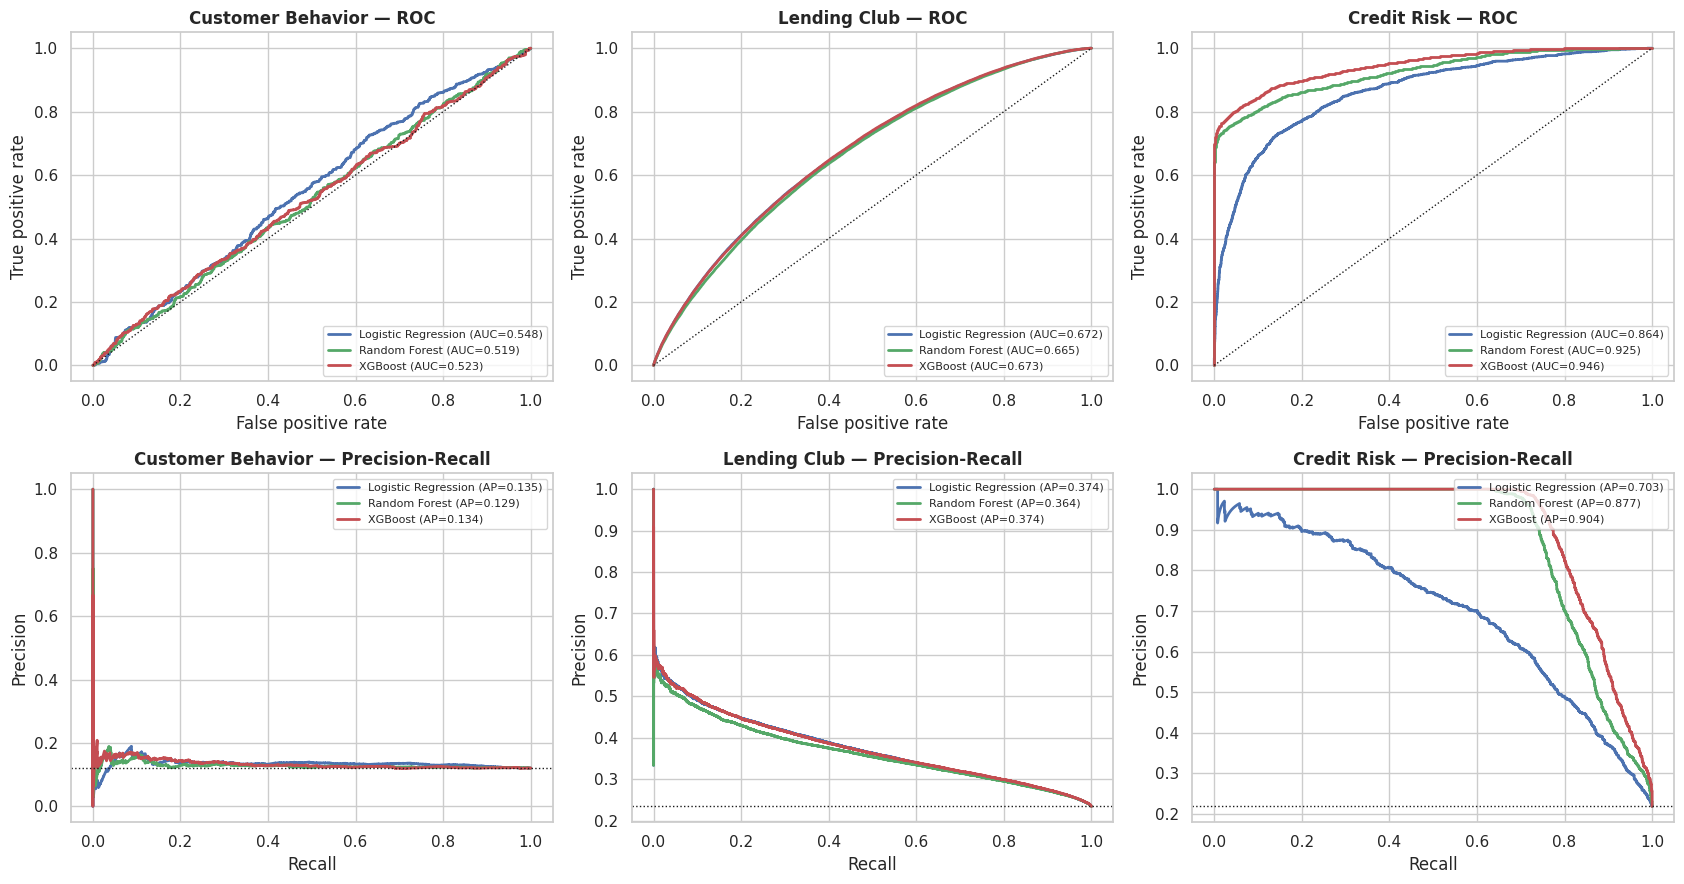

In [29]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for j, name in enumerate(DS):
    y = DATA[name]['y_test']
    for key in MODEL_KEYS:
        p = TEST_P[name][key]
        fpr, tpr, _ = roc_curve(y, p)
        axes[0, j].plot(fpr, tpr, color=MODEL_COLORS[key], lw=2, label=f'{key} (AUC={roc_auc_score(y, p):.3f})')
        pr, rc, _ = precision_recall_curve(y, p)
        axes[1, j].plot(rc, pr, color=MODEL_COLORS[key], lw=2, label=f'{key} (AP={average_precision_score(y, p):.3f})')
    axes[0, j].plot([0, 1], [0, 1], 'k:', lw=1)
    axes[0, j].set_title(f'{name} — ROC'); axes[0, j].set_xlabel('False positive rate'); axes[0, j].set_ylabel('True positive rate')
    axes[1, j].axhline(y.mean(), color='k', ls=':', lw=1)
    axes[1, j].set_title(f'{name} — Precision-Recall'); axes[1, j].set_xlabel('Recall'); axes[1, j].set_ylabel('Precision')
    axes[0, j].legend(loc='lower right', fontsize=8); axes[1, j].legend(loc='upper right', fontsize=8)
save_fig('05_roc_pr_curves')

### 5.5 Statistical uncertainty — bootstrap confidence intervals
Test-set differences between models can be smaller than sampling noise. 95 % percentile bootstrap intervals are computed for ROC-AUC and PR-AUC on a random subsample of at most `BOOT_CAP` test rows (the interval width therefore refers to that subsample size). Intervals that overlap — or that include the no-skill value (ROC-AUC = 0.5) — mean the models cannot be reliably ranked. (The marker is the full-test-set value; if it falls outside its own interval — possible for weak models, whose bootstrap distribution is biased — the whisker on that side is drawn with zero length.)

,Dataset,Model,ROC-AUC,ROC 2.5%,ROC 97.5%,PR-AUC,PR 2.5%,PR 97.5%
0,Customer Behavior,Logistic Regression,0.5476,0.5372,0.5537,0.1353,0.1309,0.1400
1,Customer Behavior,Random Forest,0.5188,0.5100,0.5270,0.1294,0.1253,0.1348
2,Customer Behavior,XGBoost,0.5226,0.5149,0.5320,0.1340,0.1302,0.1399
3,Lending Club,Logistic Regression,0.6722,0.6689,0.6798,0.3743,0.3655,0.3834
4,Lending Club,Random Forest,0.6646,0.6612,0.6711,0.3639,0.3556,0.3697
5,Lending Club,XGBoost,0.6728,0.6693,0.6797,0.3743,0.3649,0.3808
6,Credit Risk,Logistic Regression,0.8642,0.8520,0.8757,0.7031,0.6743,0.7270
7,Credit Risk,Random Forest,0.9248,0.9150,0.9340,0.8773,0.8620,0.8899
8,Credit Risk,XGBoost,0.9456,0.9394,0.9531,0.9037,0.8915,0.9147


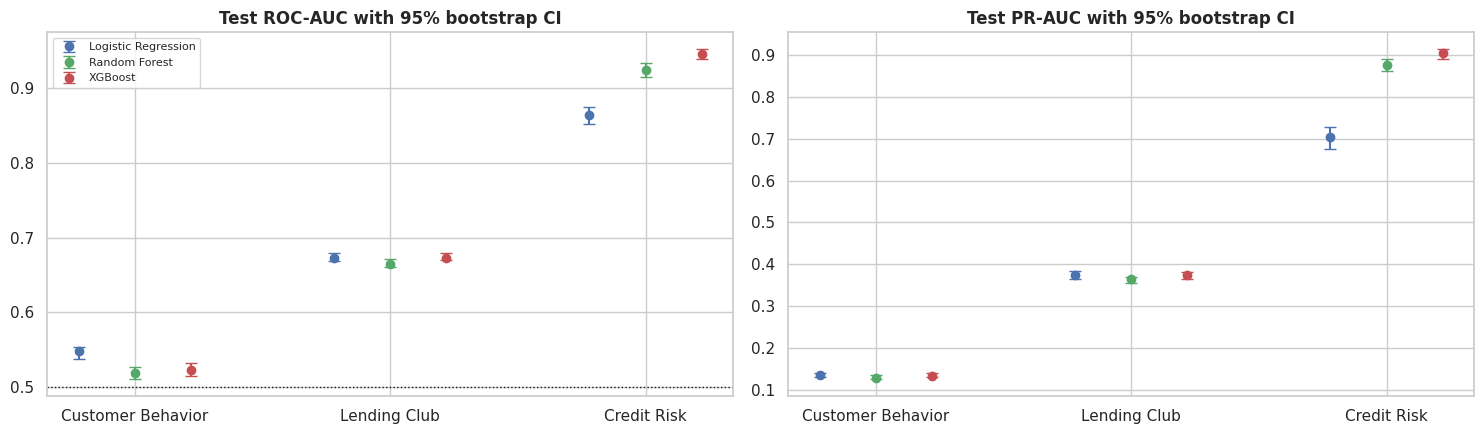

In [30]:
def bootstrap_ci(y, p, n=BOOT_N, cap=BOOT_CAP, seed=SEED):
    rng = np.random.default_rng(seed)
    if len(y) > cap:
        sel = rng.choice(len(y), cap, replace=False); y, p = y[sel], p[sel]
    rocs, prs = [], []
    for _ in range(n):
        b = rng.integers(0, len(y), len(y))
        if y[b].min() == y[b].max():
            continue
        rocs.append(roc_auc_score(y[b], p[b])); prs.append(average_precision_score(y[b], p[b]))
    return np.percentile(rocs, [2.5, 97.5]), np.percentile(prs, [2.5, 97.5])

ci_rows = []
for name in DS:
    y = DATA[name]['y_test']
    for key in MODEL_KEYS:
        r_ci, p_ci = bootstrap_ci(y, TEST_P[name][key])
        ci_rows.append({'Dataset': name, 'Model': key,
                        'ROC-AUC': roc_auc_score(y, TEST_P[name][key]), 'ROC 2.5%': r_ci[0], 'ROC 97.5%': r_ci[1],
                        'PR-AUC': average_precision_score(y, TEST_P[name][key]), 'PR 2.5%': p_ci[0], 'PR 97.5%': p_ci[1]})
ci_table = pd.DataFrame(ci_rows)
display(ci_table.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for ax, (m, lo, hi) in zip(axes, [('ROC-AUC', 'ROC 2.5%', 'ROC 97.5%'), ('PR-AUC', 'PR 2.5%', 'PR 97.5%')]):
    for i, name in enumerate(DS):
        for j, key in enumerate(MODEL_KEYS):
            r = ci_table[(ci_table.Dataset == name) & (ci_table.Model == key)].iloc[0]
            x = i + (j - 1) * 0.22
            ax.errorbar(x, r[m], yerr=[[max(r[m] - r[lo], 0)], [max(r[hi] - r[m], 0)]], fmt='o', color=MODEL_COLORS[key],
                        capsize=4, label=key if i == 0 else None)
    ax.set_xticks(range(3)); ax.set_xticklabels(DS); ax.set_title(f'Test {m} with 95% bootstrap CI')
    if m == 'ROC-AUC': ax.axhline(0.5, color='k', ls=':', lw=1)
axes[0].legend(fontsize=8)
save_fig('05_bootstrap_ci')

### 5.6 Permutation importance (best model per dataset, validation sample)
Permutation importance measures how much **PR-AUC drops** when one feature is shuffled, i.e. what the selected model actually relies on. Engineered features are shuffled independently of their source columns, so correlated features can share/mask importance.

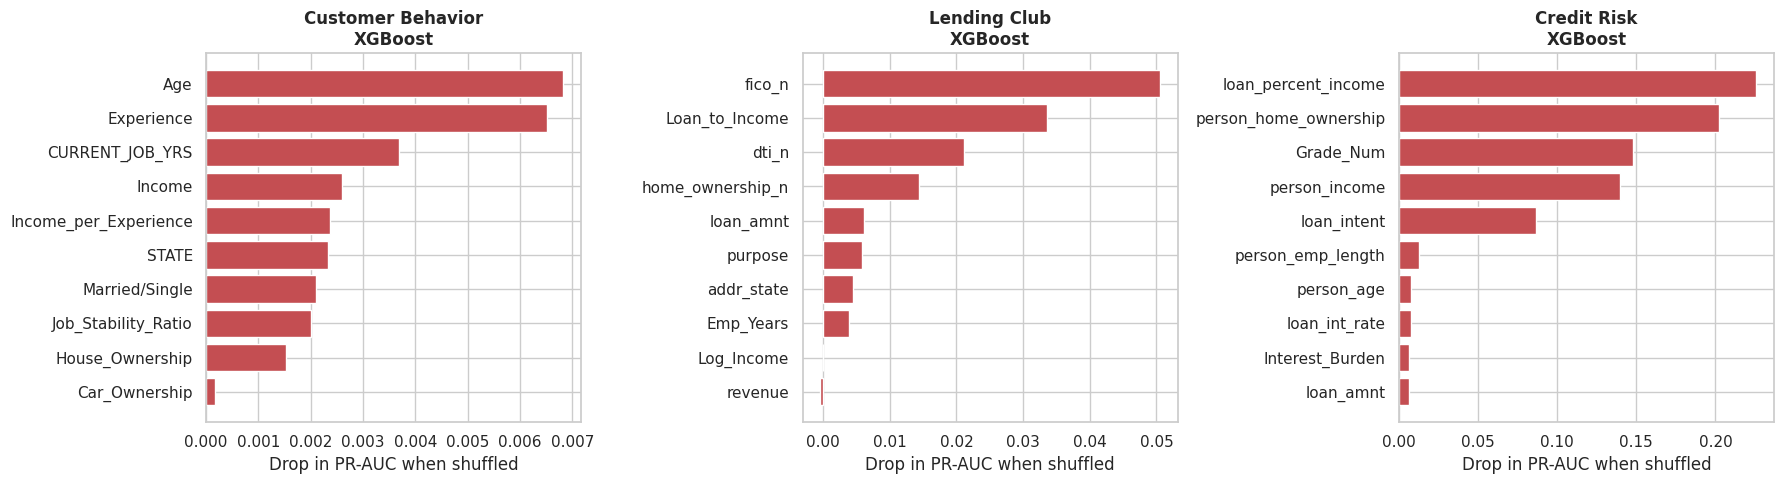

In [31]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
PERM = {}
for ax, name in zip(axes, DS):
    d = DATA[name]; pipe = MODELS[name][BEST[name]]
    n_s = min(PERM_SAMPLE, len(d['y_val']))
    idx = np.random.default_rng(SEED).choice(len(d['y_val']), n_s, replace=False)
    pi = permutation_importance(pipe, d['X_val'].iloc[idx], d['y_val'][idx], scoring='average_precision',
                                n_repeats=3, random_state=SEED, n_jobs=1)
    s = pd.Series(pi.importances_mean, index=d['X_val'].columns).sort_values(ascending=False)
    PERM[name] = s
    top = s.head(10)[::-1]
    ax.barh(top.index, top.values, color=MODEL_COLORS[BEST[name]])
    ax.set_title(f'{name}\n{BEST[name]}'); ax.set_xlabel('Drop in PR-AUC when shuffled')
save_fig('05_permutation_importance')

### 5.7 SHAP explanations (XGBoost models)
SHAP values (TreeSHAP) show how each feature pushes an individual prediction up (red = high feature value → higher default risk contribution when points lie to the right) or down. If `shap.TreeExplainer` is incompatible with the installed XGBoost version, XGBoost's built-in TreeSHAP (`pred_contribs`) is used instead — it computes the same quantity. SHAP explains the **model**, not causal effects in the real world.

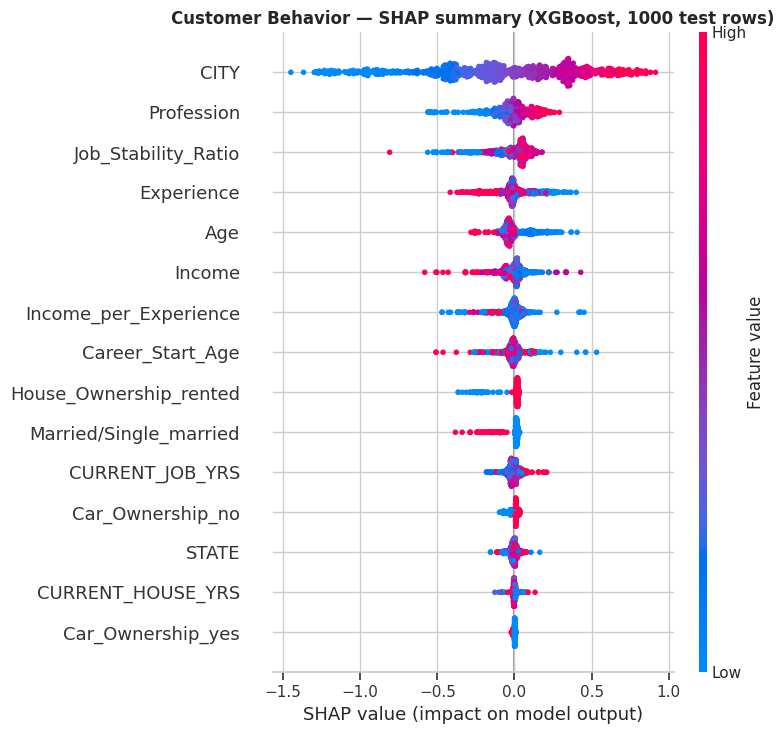

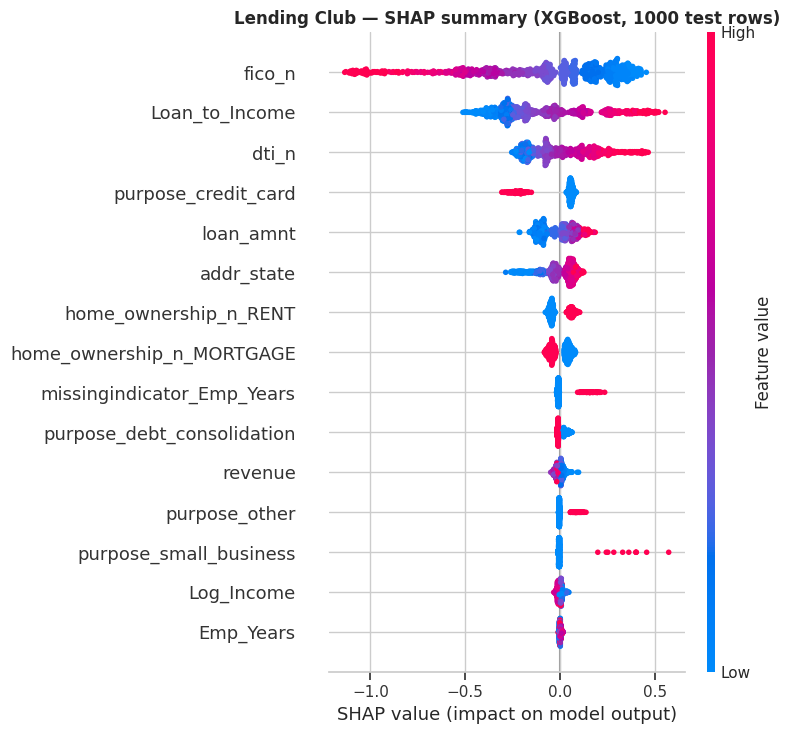

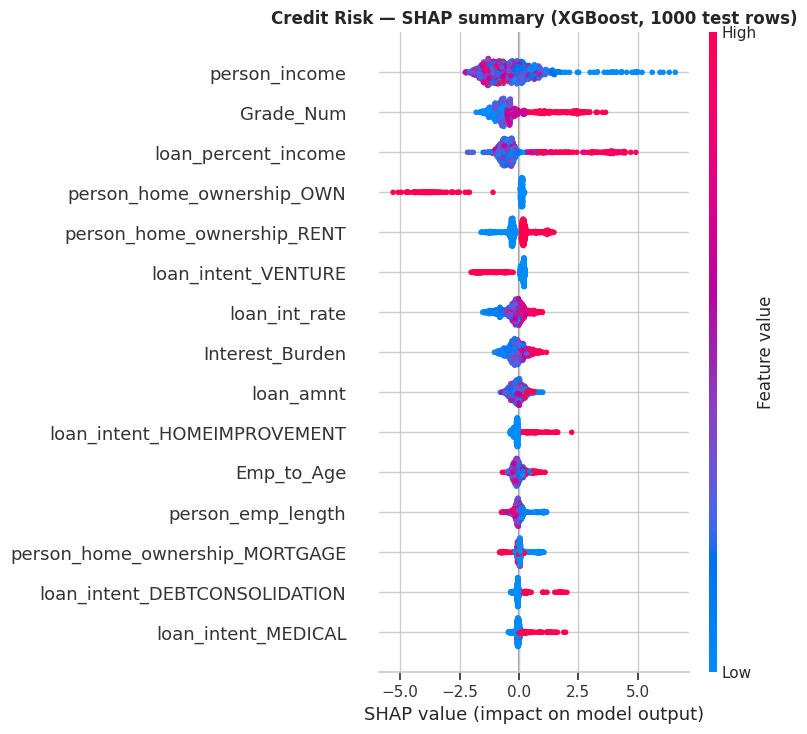

,Customer Behavior,Lending Club,Credit Risk
Age,0.0608,NaN,NaN
CITY,0.4075,NaN,NaN
Career_Start_Age,0.0409,NaN,NaN
Experience,0.0779,NaN,NaN
Grade_Num,NaN,NaN,0.8537
House_Ownership_rented,0.0321,NaN,NaN
Income,0.0487,NaN,NaN
Income_per_Experience,0.0420,NaN,NaN
Interest_Burden,NaN,NaN,0.2748
Job_Stability_Ratio,0.0816,NaN,NaN


In [32]:
if RUN_SHAP:
    import shap
    SHAP_TOP = {}
    for name in DS:
        d = DATA[name]; pipe = MODELS[name]['XGBoost']
        Xs = d['X_test'].sample(n=min(SHAP_SAMPLE, len(d['X_test'])), random_state=SEED)
        Z = pipe.named_steps['prep'].transform(Xs)
        Z = np.asarray(Z.toarray() if hasattr(Z, 'toarray') else Z, dtype='float64')
        names = short_names(pipe.named_steps['prep'].get_feature_names_out())
        mdl = pipe.named_steps['model']
        try:
            sv = shap.TreeExplainer(mdl).shap_values(Z)
        except Exception as e:
            print(f'shap.TreeExplainer failed for {name} ({type(e).__name__}); using XGBoost native TreeSHAP.')
            import xgboost as xgb
            sv = mdl.get_booster().predict(xgb.DMatrix(Z), pred_contribs=True)[:, :-1]
        if isinstance(sv, list): sv = sv[-1]
        sv = np.asarray(sv)
        if sv.ndim == 3: sv = sv[:, :, -1]
        plt.figure(figsize=(9, 6))
        shap.summary_plot(sv, Z, feature_names=names, max_display=15, show=False)
        plt.title(f'{name} — SHAP summary (XGBoost, {len(Z)} test rows)')
        save_fig(f'05_shap_{name.lower().replace(" ", "_")}')
        SHAP_TOP[name] = pd.Series(np.abs(sv).mean(axis=0), index=names).sort_values(ascending=False).head(10)
    display(pd.DataFrame(SHAP_TOP).round(4))
else:
    print('SHAP skipped (RUN_SHAP = False).')

### 5.8 Segment view — how risk-ranked groups behave (best model per dataset, test set)
Test applicants are ranked by predicted probability and cut into 10 equal-size groups (deciles). If the model ranks risk well, the observed default rate rises from decile 1 to decile 10.

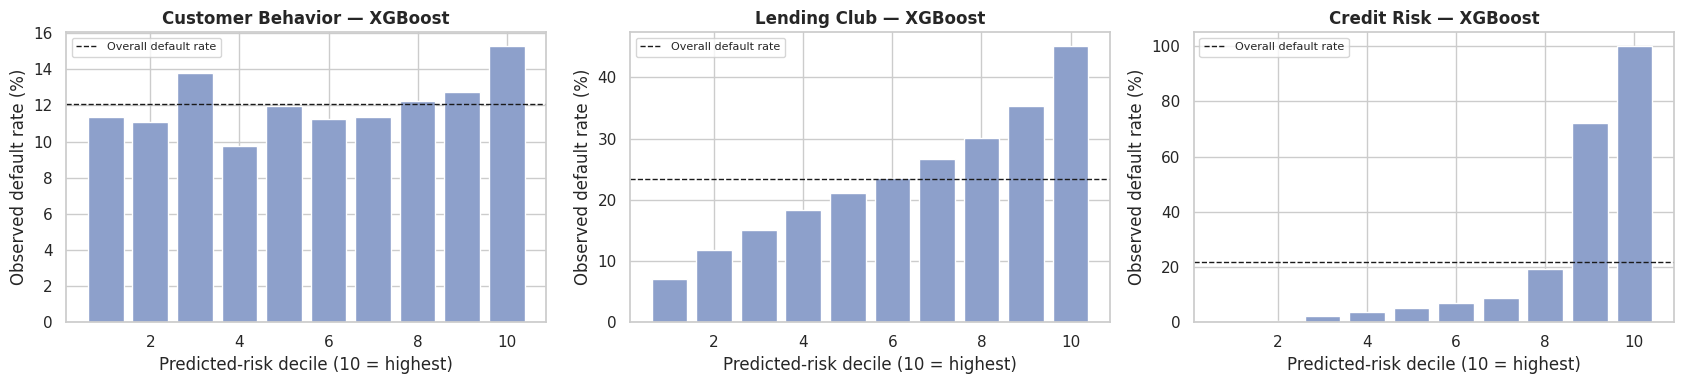

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
DECILES = {}
for ax, name in zip(axes, DS):
    y = DATA[name]['y_test']; p = TEST_P[name][BEST[name]]
    dec = pd.qcut(pd.Series(p).rank(method='first'), 10, labels=False) + 1
    t = pd.DataFrame({'decile': dec, 'y': y}).groupby('decile')['y'].mean() * 100
    DECILES[name] = t
    ax.bar(t.index, t.values, color='#8DA0CB')
    ax.axhline(y.mean() * 100, color='k', ls='--', lw=1, label='Overall default rate')
    ax.set_xlabel('Predicted-risk decile (10 = highest)'); ax.set_ylabel('Observed default rate (%)')
    ax.set_title(f'{name} — {BEST[name]}'); ax.legend(fontsize=8)
save_fig('05_risk_deciles')

### 5.9 Leakage and robustness audits
These checks test whether the headline numbers could be inflated. They are **sensitivity analyses** and are not used for model selection.

**(a) Customer Behavior — naive random split vs profile-disjoint split.** Same baseline model configurations, same 60 % training size; the only difference is whether identical feature profiles may appear on both sides of the split.

Share of naive-random TEST rows whose exact profile also occurs in TRAIN: 85.7%  (profile-disjoint split: 0.0%)


,Model,Split,ROC-AUC,PR-AUC
0,Logistic Regression,Naive random,0.6251,0.1940
1,Logistic Regression,Profile-disjoint,0.5230,0.1325
2,Random Forest,Naive random,0.8598,0.5104
3,Random Forest,Profile-disjoint,0.5152,0.1297
4,XGBoost,Naive random,0.7769,0.3716
5,XGBoost,Profile-disjoint,0.5220,0.1351


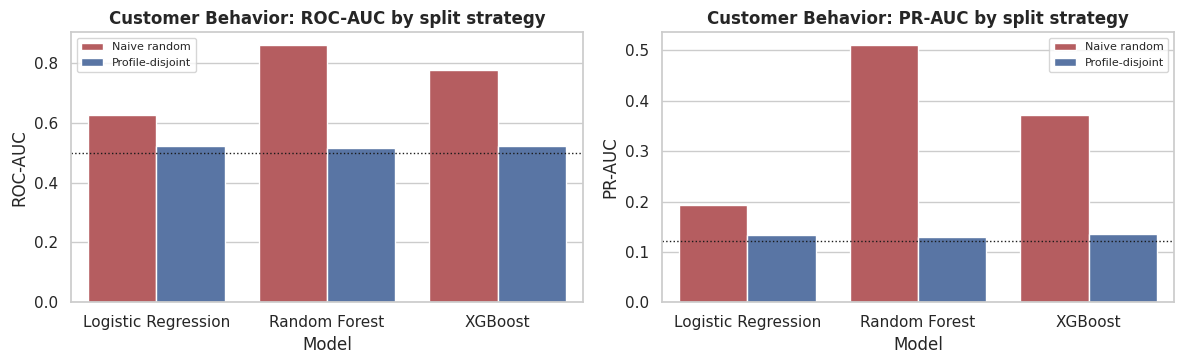

11311

In [34]:
c = clean['Customer Behavior']
y_all, pid = c['Risk_Flag'].values, c['profile_id'].values
a_tr, a_te = train_test_split(np.arange(len(c)), train_size=0.6, test_size=0.2, stratify=y_all, random_state=SEED)
seen_naive = float(pd.Series(pid[a_te]).isin(set(pid[a_tr])).mean())
Xn_tr, Xn_te = prepare_X('Customer Behavior', c.iloc[a_tr]), prepare_X('Customer Behavior', c.iloc[a_te])
yn_tr, yn_te = y_all[a_tr], y_all[a_te]
d = DATA['Customer Behavior']

rows = []
for key in MODEL_KEYS:
    # (1) naive stratified random split (profiles may appear in both train and test)
    pipe = make_pipeline('Customer Behavior', key)
    if key == 'XGBoost':
        pipe.set_params(model__scale_pos_weight=float((yn_tr == 0).sum() / (yn_tr == 1).sum()))
    pipe.fit(Xn_tr, yn_tr)
    p = pipe.predict_proba(Xn_te)[:, 1]
    rows.append({'Model': key, 'Split': 'Naive random', 'ROC-AUC': roc_auc_score(yn_te, p),
                 'PR-AUC': average_precision_score(yn_te, p)})
    # (2) profile-disjoint split used in this study (same untuned configuration, evaluated on the test partition)
    pipe = make_pipeline('Customer Behavior', key).fit(d['X_train'], d['y_train'])
    p = pipe.predict_proba(d['X_test'])[:, 1]
    rows.append({'Model': key, 'Split': 'Profile-disjoint', 'ROC-AUC': roc_auc_score(d['y_test'], p),
                 'PR-AUC': average_precision_score(d['y_test'], p)})
    del pipe; gc.collect()

audit_a = pd.DataFrame(rows)
print(f'Share of naive-random TEST rows whose exact profile also occurs in TRAIN: {seen_naive:.1%}  (profile-disjoint split: 0.0%)')
display(audit_a.round(4))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, m in zip(axes, ['ROC-AUC', 'PR-AUC']):
    sns.barplot(data=audit_a, x='Model', y=m, hue='Split', ax=ax, palette=['#C44E52', '#4C72B0'])
    ax.set_title(f'Customer Behavior: {m} by split strategy'); ax.legend(fontsize=8)
axes[0].axhline(0.5, color='k', ls=':', lw=1)
axes[1].axhline(d['y_test'].mean(), color='k', ls=':', lw=1)
save_fig('05_audit_customer_split')
del Xn_tr, Xn_te; gc.collect()

**(b) Credit Risk — are `loan_grade` and `loan_int_rate` leakage-sensitive?** Both are produced by the lender's own underwriting and may already encode its default expectation. XGBoost (same tuned parameters) is re-fitted **without** `Grade_Num`, `loan_int_rate` and `Interest_Burden` and compared on the test set.

In [35]:
d = DATA['Credit Risk']
drop_cols = ['Grade_Num', 'loan_int_rate', 'Interest_Burden']
feat_b = {k: [c for c in v if c not in drop_cols] for k, v in FEATURES['Credit Risk'].items()}
cols_b = feat_b['num'] + feat_b['low'] + feat_b['high']
pipe_b = make_pipeline('Credit Risk', 'XGBoost', feat=feat_b).set_params(**BEST_PARAMS['Credit Risk']['XGBoost'])
pipe_b.fit(d['X_train'][cols_b], d['y_train'])
p_b = pipe_b.predict_proba(d['X_test'][cols_b])[:, 1]
audit_b = pd.DataFrame([
    {'Credit Risk XGBoost variant': 'All features (study model)', **{k: v for k, v in metric_row(d['y_test'], TEST_P['Credit Risk']['XGBoost'], 0.5).items() if k in ('ROC-AUC', 'PR-AUC')}},
    {'Credit Risk XGBoost variant': 'Without loan_grade / loan_int_rate-derived features', **{k: v for k, v in metric_row(d['y_test'], p_b, 0.5).items() if k in ('ROC-AUC', 'PR-AUC')}}])
display(audit_b.round(4))
del pipe_b; gc.collect()

,Credit Risk XGBoost variant,ROC-AUC,PR-AUC
0,All features (study model),0.9456,0.9037
1,Without loan_grade / loan_int_rate-derived features,0.9081,0.8260


110

**(c) Lending Club — chronological vs random evaluation.** XGBoost (same tuned parameters, same training size) is trained on a random sample of loans from *all* eligible months and tested on a disjoint random sample. If this looks better than the chronological test result, part of the chronological gap is time drift rather than model weakness.

In [36]:
lc = clean['Lending Club']
n_test_r = min(150_000, len(lc) // 5)
n_train_r = min(LC_TRAIN_CAP, len(lc) - n_test_r)
r_tr, r_te = train_test_split(np.arange(len(lc)), train_size=n_train_r, test_size=n_test_r,
                              stratify=lc['Default'].values, random_state=SEED)
Xr_tr, Xr_te = prepare_X('Lending Club', lc.iloc[r_tr]), prepare_X('Lending Club', lc.iloc[r_te])
yr_tr, yr_te = lc['Default'].values[r_tr].astype(int), lc['Default'].values[r_te].astype(int)
pipe_c = make_pipeline('Lending Club', 'XGBoost').set_params(**BEST_PARAMS['Lending Club']['XGBoost'])
pipe_c.set_params(model__scale_pos_weight=float((yr_tr == 0).sum() / (yr_tr == 1).sum())).fit(Xr_tr, yr_tr)
p_c = pipe_c.predict_proba(Xr_te)[:, 1]
audit_c = pd.DataFrame([
    {'Lending Club XGBoost evaluation': 'Chronological test (study design)', 'ROC-AUC': roc_auc_score(DATA['Lending Club']['y_test'], TEST_P['Lending Club']['XGBoost']),
     'PR-AUC': average_precision_score(DATA['Lending Club']['y_test'], TEST_P['Lending Club']['XGBoost'])},
    {'Lending Club XGBoost evaluation': 'Random split (all months mixed)', 'ROC-AUC': roc_auc_score(yr_te, p_c), 'PR-AUC': average_precision_score(yr_te, p_c)}])
display(audit_c.round(4))
del pipe_c, Xr_tr, Xr_te; gc.collect()

,Lending Club XGBoost evaluation,ROC-AUC,PR-AUC
0,Chronological test (study design),0.6728,0.3743
1,Random split (all months mixed),0.6640,0.3221


119

### 5.10 Auto-generated results summary
Text below is built from the tables computed above — nothing is typed in by hand.

In [37]:
lines = ['#### Results summary (generated from this run)\n']
for name in DS:
    best = BEST[name]
    r = test_main[(test_main.Dataset == name) & (test_main.Model == best)].iloc[0]
    ci = ci_table[(ci_table.Dataset == name) & (ci_table.Model == best)].iloc[0]
    prev = DATA[name]['y_test'].mean()
    lines.append(f'* **{name}** — selected model (validation PR-AUC): **{best}**. Test ROC-AUC = {r["ROC-AUC"]:.3f} '
                 f'(95% CI {ci["ROC 2.5%"]:.3f}–{ci["ROC 97.5%"]:.3f}), PR-AUC = {r["PR-AUC"]:.3f} (no-skill = {prev:.3f}), '
                 f'precision = {r["Precision"]:.3f}, recall = {r["Recall"]:.3f}, F1 = {r["F1"]:.3f} at threshold {r["Threshold"]:.3f}.')
weak = [n for n in DS if ci_table[(ci_table.Dataset == n) & (ci_table.Model == BEST[n])].iloc[0]['ROC 2.5%'] < 0.60]
if weak:
    lines.append(f'\n* ⚠ For **{", ".join(weak)}** the lower bound of the bootstrap ROC-AUC interval of the selected model is below 0.60 — '
                 'discrimination is weak or unreliable on unseen data; treat any prediction as illustrative only.')
na = audit_a.pivot(index='Model', columns='Split', values='ROC-AUC')
lines.append(f'\n* Customer Behavior leakage audit: {seen_naive:.1%} of naive-random test rows share an exact profile with training rows. '
             'Untuned ROC-AUC, naive random split vs profile-disjoint split: ' +
             '; '.join(f"{k}: {row['Naive random']:.3f} vs {row['Profile-disjoint']:.3f}" for k, row in na.iterrows()) + '.')
display(Markdown('\n'.join(lines)))

#### Results summary (generated from this run)

* **Customer Behavior** — selected model (validation PR-AUC): **XGBoost**. Test ROC-AUC = 0.523 (95% CI 0.515–0.532), PR-AUC = 0.134 (no-skill = 0.121), precision = 0.120, recall = 0.979, F1 = 0.214 at threshold 0.167.
* **Lending Club** — selected model (validation PR-AUC): **XGBoost**. Test ROC-AUC = 0.673 (95% CI 0.669–0.680), PR-AUC = 0.374 (no-skill = 0.234), precision = 0.336, recall = 0.621, F1 = 0.436 at threshold 0.482.
* **Credit Risk** — selected model (validation PR-AUC): **XGBoost**. Test ROC-AUC = 0.946 (95% CI 0.939–0.953), PR-AUC = 0.904 (no-skill = 0.219), precision = 0.970, recall = 0.738, F1 = 0.838 at threshold 0.728.

* ⚠ For **Customer Behavior** the lower bound of the bootstrap ROC-AUC interval of the selected model is below 0.60 — discrimination is weak or unreliable on unseen data; treat any prediction as illustrative only.

* Customer Behavior leakage audit: 85.7% of naive-random test rows share an exact profile with training rows. Untuned ROC-AUC, naive random split vs profile-disjoint split: Logistic Regression: 0.625 vs 0.523; Random Forest: 0.860 vs 0.515; XGBoost: 0.777 vs 0.522.

---
# 6. Interactive loan-risk prediction interface (Colab widgets)
Pick a dataset, edit the applicant fields, and press **Predict**. The **selected best model** of that dataset (Section 5.1) scores the application using exactly the same engineered features and fitted preprocessing as in training. **Fill with random test row** loads a held-out example (and shows its true outcome) so you can try the form quickly.

How to read the output:
* The probability is a **ranking score** from a class-weighted model, not a calibrated real-world default probability.
* *Risk band*: **High** if the score ≥ the model's validation-tuned threshold, **Medium** if between half the threshold and the threshold, **Low** otherwise.
* Each dataset has its own schema; the fields shown are the raw inputs of that dataset only.

In [38]:
import ipywidgets as widgets

# Reliability flag for the interface: lower bootstrap bound of the selected model's ROC-AUC (Section 5.5)
WEAK = {n: bool(ci_table[(ci_table.Dataset == n) & (ci_table.Model == BEST[n])].iloc[0]['ROC 2.5%'] < 0.60) for n in DS}

def band_for(p, thr):
    if p >= thr:
        return 'High', '#C44E52'
    if p >= 0.5 * thr:
        return 'Medium', '#E0A030'
    return 'Low', '#55A868'

def score_application(name, row):
    X = prepare_X(name, pd.DataFrame([row]))
    p = float(MODELS[name][BEST[name]].predict_proba(X)[0, 1])
    return p, THR[name][BEST[name]]

def render_result(name, p, thr, actual=None):
    band, color = band_for(p, thr)
    pct = p * 100
    warn = ''
    if WEAK[name]:
        warn = ("<p style='color:#B00020;margin:8px 0 0'>&#9888; On held-out data this dataset's selected model showed weak or "
                "unreliable discrimination (see Section 5.5). Treat this output as illustrative only.</p>")
    act = ''
    if actual is not None:
        act = f"<p style='margin:6px 0 0'>Recorded outcome of this test row: <b>{'Default' if actual == 1 else 'Non-default'}</b></p>"
    return (f"<div style='font-family:sans-serif;border:1px solid #bbb;border-radius:8px;padding:12px;max-width:600px'>"
            f"<div><b>{name}</b> &mdash; model: {BEST[name]}</div>"
            f"<div style='margin-top:6px'>Estimated default score: <b>{pct:.1f}%</b></div>"
            f"<div style='background:#eee;height:14px;border-radius:7px;margin:6px 0'>"
            f"<div style='width:{min(pct, 100):.1f}%;background:{color};height:14px;border-radius:7px'></div></div>"
            f"<div>Risk band: <b style='color:{color}'>{band}</b> &nbsp;|&nbsp; decision threshold {thr:.3f} "
            f"&rarr; predicted class: <b>{'Default' if p >= thr else 'Non-default'}</b></div>"
            f"{act}{warn}"
            f"<p style='color:#666;font-size:12px;margin:8px 0 0'>Academic prototype - not for real lending decisions.</p></div>")

# Programmatic check that works even if widgets do not render: score one held-out row per dataset
for n in DS:
    r0 = DATA[n]['raw_test_sample'].iloc[0]
    p0, t0 = score_application(n, {c: r0[c] for c in RAW_INPUTS[n]})
    print(f'{n:18s} example test row -> score={p0:.3f} (threshold {t0:.3f}), recorded outcome={int(r0[TARGET[n]])}')

Customer Behavior  example test row -> score=0.484 (threshold 0.167), recorded outcome=0
Lending Club       example test row -> score=0.425 (threshold 0.482), recorded outcome=1
Credit Risk        example test row -> score=0.111 (threshold 0.728), recorded outcome=0


In [39]:
dataset_dd = widgets.Dropdown(options=DS, value=DS[0], description='Dataset:',
                              style={'description_width': '80px'}, layout=widgets.Layout(width='360px'))
form_box = widgets.VBox([])
hint_html = widgets.HTML('')
out = widgets.Output()
state = {'ctrls': {}}
DESC_STYLE = {'description_width': '230px'}
WIDE = widgets.Layout(width='520px')

def build_form(name):
    ctrls, hints = {}, []
    for s in DATA[name]['ui_spec']:
        if s['kind'] == 'num':
            w = widgets.FloatText(value=s['default'], description=s['col'], style=DESC_STYLE, layout=WIDE)
            hints.append(f"<tr><td>{s['col']}</td><td>{s['lo']:,.2f} &ndash; {s['hi']:,.2f}</td></tr>")
        else:
            w = widgets.Dropdown(options=s['options'], value=s['default'], description=s['col'], style=DESC_STYLE, layout=WIDE)
        ctrls[s['col']] = w
    state['ctrls'] = ctrls
    form_box.children = tuple(ctrls.values())
    hint_html.value = ("<details><summary>Typical numeric ranges in the training data (1st - 99th percentile)</summary>"
                       "<table style='font-size:12px'><tr><th align=left>Field</th><th align=left>Range</th></tr>"
                       + ''.join(hints) + '</table></details>')

def read_inputs():
    row = {}
    for k, w in state['ctrls'].items():
        row[k] = float(w.value) if isinstance(w, widgets.FloatText) else w.value
    return row

def on_predict(_=None, actual=None):
    name = dataset_dd.value
    with out:
        clear_output(wait=True)
        try:
            p, thr = score_application(name, read_inputs())
            display(HTML(render_result(name, p, thr, actual)))
        except Exception as e:
            print('Could not score this application:', type(e).__name__, e)

def on_sample(_):
    name = dataset_dd.value
    row = DATA[name]['raw_test_sample'].sample(1).iloc[0]
    for col, w in state['ctrls'].items():
        v = row[col]
        if isinstance(w, widgets.FloatText):
            if pd.notna(v):
                w.value = float(v)
        elif v in list(w.options):
            w.value = v
    on_predict(actual=int(row[TARGET[name]]))

def on_dataset_change(change):
    build_form(change['new'])
    with out:
        clear_output()

predict_btn = widgets.Button(description='Predict', button_style='primary', icon='check')
sample_btn = widgets.Button(description='Fill with random test row', icon='random')
predict_btn.on_click(on_predict)
sample_btn.on_click(on_sample)
dataset_dd.observe(on_dataset_change, names='value')

build_form(dataset_dd.value)
display(widgets.VBox([widgets.HTML('<h3>Loan-risk prediction interface</h3>'), dataset_dd, hint_html, form_box,
                      widgets.HBox([predict_btn, sample_btn]), out]))

---
# 7. Export of models, tables and figures
Saves the selected model per dataset (with its threshold and feature list), every result table as CSV, all figures, and a run-information file into one ZIP.
> To reload a saved model in another notebook you must define the same `QuantileClipper` class first (it is part of the pipeline).

In [40]:
for name in DS:
    safe = name.lower().replace(' ', '_')
    joblib.dump({'dataset': name, 'model_name': BEST[name], 'pipeline': MODELS[name][BEST[name]],
                 'threshold': THR[name][BEST[name]], 'features': list(DATA[name]['X_train'].columns),
                 'raw_inputs': RAW_INPUTS[name], 'sklearn_version': sklearn.__version__},
                OUT_DIR / f'{safe}_best_model.joblib', compress=3)

TABLES = {'selection_decisions': selection_table, 'missing_values': miss_table, 'outliers': outlier_table,
          'class_imbalance': imbalance_table, 'split_summary': split_summary, 'baseline_validation': baseline_val,
          'tuning_summary': tuning_summary.assign(**{'Best parameters': tuning_summary['Best parameters'].astype(str)}),
          'validation_baseline_vs_tuned': cmp, 'model_selection': selection_df, 'test_results_tuned_threshold': test_main,
          'test_results_threshold_0.5': test_ref, 'bootstrap_ci': ci_table, 'imbalance_comparison': imbalance_compare,
          'audit_customer_split': audit_a, 'audit_credit_leakage': audit_b, 'audit_lending_time_vs_random': audit_c}
for k, v in TABLES.items():
    v.to_csv(OUT_DIR / f'{k}.csv', index=False)

run_info = {'seed': SEED, 'quick_mode': QUICK_MODE, 'lc_train_cap': LC_TRAIN_CAP, 'tune_cap': TUNE_CAP,
            'cv_folds': CV_FOLDS, 'n_iter': N_ITER, 'lc_cutoff': LC_CUTOFF,
            'best_model_per_dataset': BEST, 'thresholds': {n: THR[n][BEST[n]] for n in DS},
            'versions': {'sklearn': sklearn.__version__, 'pandas': pd.__version__, 'numpy': np.__version__,
                         'xgboost': __import__('xgboost').__version__}}
(OUT_DIR / 'run_info.json').write_text(json.dumps(run_info, indent=2, default=str))

zip_path = '/content/Loan_Default_Project_Outputs.zip'
with zipfile.ZipFile(zip_path, 'w', zipfile.ZIP_DEFLATED) as z:
    for f in sorted(OUT_DIR.rglob('*')):
        if f.is_file():
            z.write(f, arcname=str(f.relative_to(OUT_DIR)))
print(f'Saved {zip_path} ({os.path.getsize(zip_path)/1024**2:.1f} MB) with {len(TABLES)} tables, '
      f'{len(list(FIG_DIR.glob("*.png")))} figures and 3 model files.')
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print('Download manually from the Colab Files pane (left sidebar).')

Saved /content/Loan_Default_Project_Outputs.zip (2.5 MB) with 16 tables, 22 figures and 3 model files.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# 8. Conclusions, limitations and future scope

## 8.1 Conclusions
The dataset-specific findings (which of the nine models is best, and by how much) are produced by the code above and summarised in **Section 5.10**; they are deliberately not hard-coded here. What the study establishes methodologically:

1. **All five KDD stages were carried out separately for each of the three datasets** — Selection, Preprocessing, Transformation, Data Mining and Evaluation — and the datasets were never merged. Cross-dataset comparison is therefore about *methods and metric behaviour*, not about one population being "easier" than another.
2. **The evaluation design is part of the result.** Splits were chosen to match each dataset's structure (profile-disjoint for Customer Behavior, chronological for Lending Club, stratified for Credit Risk), and all learned preprocessing lives inside pipelines fitted on training data only. The audits in Section 5.9 quantify how much a naive design would have inflated the scores — read the Section 5.2 tables together with them.
3. **Under class imbalance, accuracy is a poor yardstick.** PR-AUC (against the no-skill line = prevalence), recall/precision at a validation-tuned threshold and bootstrap intervals give a more honest picture; Section 4.5 shows where class weighting changes threshold-dependent behaviour versus ranking quality.
4. **Model comparison should respect uncertainty.** Where bootstrap intervals overlap (Section 5.5) the models cannot be ranked reliably, and where an interval for ROC-AUC approaches 0.5 the model has little demonstrable predictive value on unseen data.
5. **Interpretability** (coefficients, impurity importance, permutation importance, SHAP) shows *what each model relies on*; it does not establish causal effects.

## 8.2 Limitations
* **Different targets and populations.** `Risk_Flag`, `Default` and `loan_status` are defined differently by different sources; scores are not comparable benchmarks.
* **Customer Behavior.** In the provided file the 252 000 rows contain only 42 007 distinct feature profiles, and some identical profiles carry conflicting labels (Section 2.2). Even after profile-disjoint splitting, the available attributes may carry limited signal, `CITY` and `STATE` are not guaranteed to be consistent, and the target definition and time reference are not documented in the file.
* **Lending Club.** Only loans with a known outcome appear to be present (accepted loans only → selection bias; no information on rejected applicants); recent vintages show label-maturity effects (Section 2.4), so 2018 issues were excluded; macro-economic drift limits chronological generalisation; training used a capped, stratified sample (`LC_TRAIN_CAP`); the file has few borrower attributes (e.g. no loan grade or interest rate).
* **Credit Risk.** A small dataset (≈ 32 k rows after de-duplication) whose collection process is not documented. `loan_grade` and `loan_int_rate` are underwriting outputs; they are valid only if scoring happens after underwriting (Section 5.9b). Implausible ages/employment lengths were masked rather than corrected.
* **Imbalance and calibration.** Class weighting distorts probability scale; scores are not calibrated probabilities, and the F1-based thresholds ignore the asymmetric real-world costs of false approvals and false rejections.
* **Search budget and variance.** Hyper-parameter search used a limited number of random candidates on a subsample; results come from a single split/seed, and bootstrap intervals reflect test-sampling noise only, not training-set or seed variability.
* **Fairness and compliance.** Age, marital status and location-related variables are used as predictors in the Customer Behavior data; no fairness, disparate-impact or regulatory (e.g. adverse-action explanation) analysis was performed. The models and the widget interface **must not be used for real credit decisions**.

## 8.3 Future scope
* Probability **calibration** (Platt / isotonic) and **cost-sensitive** threshold selection using business-defined costs.
* Controlled comparison of **resampling methods** (SMOTE/ADASYN/undersampling inside cross-validation pipelines) against class weighting — not performed in this study.
* Additional learners (LightGBM, CatBoost, tabular neural networks), **stacking**, and **nested / repeated cross-validation** with multiple seeds.
* **Rolling-origin (walk-forward) validation** and **survival / time-to-default** modelling for Lending Club; drift monitoring (e.g. PSI).
* **Reject inference** to reduce selection bias; richer features (bureau data, macro-economic indicators).
* **Fairness audits** (demographic parity, equalised odds) and SHAP-based reason codes.
* Deployment as a service (Streamlit/FastAPI) with logging and monitoring.

## 8.4 References
* Fayyad, U., Piatetsky-Shapiro, G., & Smyth, P. (1996). From data mining to knowledge discovery in databases. *AI Magazine*, 17(3), 37–54.
* Breiman, L. (2001). Random forests. *Machine Learning*, 45, 5–32.
* Chen, T., & Guestrin, C. (2016). XGBoost: A scalable tree boosting system. *KDD '16*.
* Lundberg, S. M., & Lee, S.-I. (2017). A unified approach to interpreting model predictions. *NeurIPS 30*.
* Saito, T., & Rehmsmeier, M. (2015). The precision-recall plot is more informative than the ROC plot when evaluating binary classifiers on imbalanced datasets. *PLoS ONE*, 10(3).
* Pedregosa, F., et al. (2011). Scikit-learn: Machine learning in Python. *JMLR*, 12, 2825–2830.